# Quantum Fourier Transform and Quantum Phase Estimation

A from-scratch build of the two most important subroutines in quantum computing: the
**QFT** (matrix, circuit, bit-reversal trap, inverse, approximate version) and
**QPE** (exact distributions, the 8/π² floor, the precision/qubit trade-off, the
iterative variant, and what noise does to it).

Nothing here is borrowed from a library: every matrix, every circuit, every
distribution and every FFT below is built from `numpy` alone. Qiskit appears once, at
the very end, purely as an optional referee.

| Part | Topic | What you get |
|---|---|---|
| 1 | The QFT as a matrix | twiddle factors, unitarity, what it does to a basis state |
| 2 | The QFT as a circuit | H + controlled-R_k, circuit == matrix proof, gate count n(n+1)/2 |
| 3 | Bit reversal | the output-ordering trap and the SWAP layer that fixes it |
| 4 | Inverse QFT | conjugate transpose, round-trip identity to 1e-14 |
| 5 | Approximate QFT | Coppersmith's truncation: gates vs fidelity vs ε |
| 6 | QFT vs FFT | our own radix-2 FFT, and the table of why they are *not* the same thing |
| 7 | Periodic states | QFT of a subgroup gives peaks -- the seed of Shor |
| 8 | Phase estimation | eigenpair table, controlled-U^(2^j), dyadic vs generic φ |
| 9 | The Dirichlet kernel | the sinc² formula and the 8/π² = 0.8106 floor |
| 10 | Precision vs qubits | the money analysis: success probability, error, depth |
| 11 | Iterative QPE | one ancilla, feed-forward, identical bits to full QPE |
| 12 | Noise | why more counting qubits can make the answer *worse* |
| 13 | Two pictures | P(exact) on the (φ, t) grid, and a shot histogram |
| 14 | Self-tests | 70+ assertions that the notebook is telling the truth |
| 15 | Qiskit (optional) | the same numbers from the real thing, skipped cleanly if absent |

**How to read it.** Every number on screen is computed by the cell above it, and every
claim in the prose is checked by the self-test cell. Where the honest answer is "it
depends on φ", we say so instead of smoothing it over.


In [1]:
import math

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 110, "font.size": 10,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True})

# --------------------------------------------------------------------------
# Conventions. Read these twice; almost every QFT bug is a convention bug.
#
#  * ENDIANNESS. Qubit 0 is the LEFT-MOST tensor factor, i.e. the most
#    significant bit. |b0 b1 ... b_{n-1}> has integer index
#        index = sum_k b_k * 2**(n-1-k).
#    This is kron order (the same convention as the Bell notebook in this
#    folder). Qiskit labels q0 as the LEAST significant bit instead; Part 15
#    shows exactly where that matters.
#
#  * PHASE SIGN. We use the POSITIVE exponent:
#        R_k = diag(1, exp(+2*pi*i / 2**k))
#        F[j, k] = exp(+2*pi*i*j*k / N) / sqrt(N),  N = 2**n
#    so the forward transform carries +i and the inverse is its conjugate
#    transpose (which carries -i). Some textbooks put the minus sign in the
#    forward transform; their circuit is our circuit with every rotation
#    negated, and it estimates -phi.
# --------------------------------------------------------------------------
Y = np.array([[0.0, -1.0j], [1.0j, 0.0]], dtype=complex)
I2 = np.eye(2, dtype=complex)
H = np.array([[1.0, 1.0], [1.0, -1.0]], dtype=complex) / math.sqrt(2.0)
X = np.array([[0.0, 1.0], [1.0, 0.0]], dtype=complex)
Z = np.array([[1.0, 0.0], [0.0, -1.0]], dtype=complex)
SWAP = np.array([[1, 0, 0, 0], [0, 0, 1, 0], [0, 1, 0, 0], [0, 0, 0, 1]], dtype=complex)
PAULIS = (X, Y, Z)


def ket(index, n):
    """|index> on n qubits, in our big-endian kron ordering."""
    v = np.zeros(2 ** n, dtype=complex)
    v[index] = 1.0
    return v


def random_state(dim, rng):
    v = rng.normal(size=dim) + 1j * rng.normal(size=dim)
    return v / np.linalg.norm(v)


def apply_unitary(psi, U, targets, n):
    """Apply a k-qubit matrix U to the qubits listed in `targets` (index 0 = MSB)."""
    k = len(targets)
    tensor = np.asarray(psi, dtype=complex).reshape([2] * n)
    tensor = np.moveaxis(tensor, targets, list(range(k)))
    tensor = (U @ tensor.reshape(2 ** k, -1)).reshape([2] * k + [2] * (n - k))
    return np.moveaxis(tensor, list(range(k)), targets).reshape(2 ** n)


def controlled(V):
    """Controlled-V on two qubits, control first: |0><0| (x) I + |1><1| (x) V."""
    d = V.shape[0]
    C = np.eye(2 * d, dtype=complex)
    C[d:, d:] = V
    return C


def R(k):
    """R_k = diag(1, exp(2*pi*i/2^k)) -- positive exponent by our convention."""
    return np.diag([1.0 + 0.0j, np.exp(2.0j * math.pi / 2 ** k)])


def phase_gate(theta):
    """diag(1, exp(i*theta)). Its eigenvalue on |1> is exp(i*theta), i.e. phi = theta/(2*pi)."""
    return np.diag([1.0 + 0.0j, np.exp(1.0j * theta)])


def bit_reverse_index(j, nbits):
    return int(format(j, "0%db" % nbits)[::-1], 2)


def bit_reverse_perm(nbits):
    return np.array([bit_reverse_index(j, nbits) for j in range(2 ** nbits)])


def ray_overlap(a, b):
    """Global-phase-free similarity of two vectors: |<a|b>| / (|a||b|). 1.0 == same state."""
    return float(abs(np.vdot(a, b)) / (np.linalg.norm(a) * np.linalg.norm(b)))


def phase_turns(v, tol=1e-12):
    """Phase of every amplitude, in turns (units of 2*pi). Silent about zero amplitudes."""
    out = np.full(np.asarray(v).size, np.nan)
    for i, z in enumerate(np.asarray(v)):
        if abs(z) > tol:
            out[i] = (math.atan2(z.imag, z.real) / (2.0 * math.pi)) % 1.0
    return out


rng = np.random.default_rng(20261107)          # every figure in here is reproducible
print("R_1 == Z :", np.allclose(R(1), Z), "| R_2 == S :", np.allclose(R(2), phase_gate(math.pi / 2)),
      "| R_3 == T :", np.allclose(R(3), phase_gate(math.pi / 4)))
print("H is unitary and Hermitian :", np.allclose(H.conj().T @ H, I2), np.allclose(H, H.conj().T))
print("SWAP is its own inverse     :", np.allclose(SWAP @ SWAP, np.eye(4)))
print("controlled(Z) == CNOT-in-basis :", np.allclose(controlled(Z), np.diag([1, 1, 1, -1])))
print("endianness check: |01> on 3 qubits has index", int(np.nonzero(ket(1, 3))[0][0]),
      "(q0 is the most significant bit, so |001> would be index 4)")


R_1 == Z : True | R_2 == S : True | R_3 == T : True
H is unitary and Hermitian : True True
SWAP is its own inverse     : True
controlled(Z) == CNOT-in-basis : True
endianness check: |01> on 3 qubits has index 1 (q0 is the most significant bit, so |001> would be index 4)


## Part 1 -- the QFT as a matrix

On $n$ qubits the space has dimension $N = 2^n$ and the QFT is the $N\times N$ matrix

$$F\;=\;\frac{1}{\sqrt N}\sum_{j,k=0}^{N-1} e^{2\pi i\,jk/N}\,\lvert j\rangle\langle k\rvert ,
\qquad F[j,k]=\frac{e^{2\pi i\,jk/N}}{\sqrt N}.$$

Three properties to hold on to for the rest of the notebook.

* **It is the DFT.** The same object as the discrete Fourier transform of signal
  processing, applied to a vector of amplitudes instead of a vector of samples. Part 6
  makes that comparison precise -- and shows where it breaks down.
* **It is unitary and symmetric.** $F^\dagger F = I$ (so it is a legal quantum
  evolution) and $F = F^{\mathsf T}$ (the circuit we build later is symmetric under
  exchanging input and output wires, which is why reversing the circuit gives the
  inverse).
* **A basis state becomes a phase ramp.** $F\lvert j\rvert$ has constant magnitude
  $1/\sqrt N$ and phase $2\pi jk/N$ in the output index $k$. That linear-in-$k$ phase
  is *the* thing QPE reads out, so we will print it explicitly rather than hide it
  inside a plot.


In [2]:
def qft_matrix(n):
    """Exact tensor-product QFT on n qubits: F[j,k] = exp(2*pi*i*j*k/N)/sqrt(N)."""
    N = 2 ** n
    jk = np.outer(np.arange(N), np.arange(N))
    return np.exp(2.0j * math.pi * jk / N) / math.sqrt(N)


def dft_matrix(N):
    """Same formula written for a plain dimension N, so we can compare against an FFT."""
    jk = np.outer(np.arange(N), np.arange(N))
    return np.exp(2.0j * math.pi * jk / N) / math.sqrt(N)


print("QFT(2) in units of 1/2, entries written as exp(2*pi*i*theta):")
F2 = qft_matrix(2)
for row in F2:
    print("   ", "  ".join("%+0.3f%s%0.3fi" % (z.real, "+" if z.imag >= 0 else "-", abs(z.imag)) for z in row))

for n in (2, 3, 4):
    F = qft_matrix(n)
    N = 2 ** n
    unitary = np.allclose(F.conj().T @ F, np.eye(N), atol=1e-12)
    symmetric = np.allclose(F, F.T, atol=1e-12)
    flat = np.allclose(np.abs(F), 1.0 / math.sqrt(N), atol=1e-12)
    print("n=%d  unitary %s | symmetric %s | every |entry| = 1/sqrt(N) %s | det-modulus %.12f"
          % (n, unitary, symmetric, flat, abs(np.linalg.det(F))))

# What a basis state turns into: flat magnitudes, linear phase ramp.
n, N = 4, 16
F = qft_matrix(n)
print("\nF|0> (n=4): magnitudes all %.6f, phases in turns all %.1f -> uniform, no information"
      % (np.abs(F[:, 0]).mean(), 0.0))
for j in (1, 3):
    col = F[:, j]
    turns = (np.angle(col) / (2 * math.pi)) % 1.0
    expected = (j * np.arange(N) / N) % 1.0
    print("F|%-2d> : |amp| flat at %.6f ; phase ramp matches 2*pi*j*k/N pointwise: %s"
          % (j, np.abs(col).mean(), np.allclose(turns, expected, atol=1e-12)))
    print("        phases (turns) k=0..7:", np.round(turns[:8], 4))
    slope = np.unwrap(np.angle(col)) / (2 * math.pi)
    print("        slope of the unwrapped ramp = %.6f = j = %d  <-- QPE measures exactly this"
          % (np.polyfit(np.arange(N), slope, 1)[0], j))


QFT(2) in units of 1/2, entries written as exp(2*pi*i*theta):
    +0.500+0.000i  +0.500+0.000i  +0.500+0.000i  +0.500+0.000i
    +0.500+0.000i  +0.000+0.500i  -0.500+0.000i  -0.000-0.500i
    +0.500+0.000i  -0.500+0.000i  +0.500-0.000i  -0.500+0.000i
    +0.500+0.000i  -0.000-0.500i  -0.500+0.000i  +0.000+0.500i
n=2  unitary True | symmetric True | every |entry| = 1/sqrt(N) True | det-modulus 1.000000000000
n=3  unitary True | symmetric True | every |entry| = 1/sqrt(N) True | det-modulus 1.000000000000
n=4  unitary True | symmetric True | every |entry| = 1/sqrt(N) True | det-modulus 1.000000000000

F|0> (n=4): magnitudes all 0.250000, phases in turns all 0.0 -> uniform, no information
F|1 > : |amp| flat at 0.250000 ; phase ramp matches 2*pi*j*k/N pointwise: True
        phases (turns) k=0..7: [0.     0.0625 0.125  0.1875 0.25   0.3125 0.375  0.4375]
        slope of the unwrapped ramp = 0.062500 = j = 1  <-- QPE measures exactly this
F|3 > : |amp| flat at 0.250000 ; phase ramp matches 

## Part 2 -- the QFT as a circuit

$F$ is an $N\times N$ matrix, which by itself says nothing about how to *build* it. The
beautiful fact (Barenco et al., Nielsen & Chuang 3.5.1) is that it needs only
single-qubit Hadamards and controlled phase rotations:

$$\text{for } p = 0,\dots,n-1:\quad
H_p,\ \text{then for } q = p+1,\dots,n-1:\ \mathrm{cR}_{\,q-p+1}\ \text{with control } q,\ \text{target } p .$$

The rotation used between wires $p$ and $q$ is $R_{q-p+1}$, so the *distance* between
the wires sets the *angle*: neighbours contribute $\pi$, next-neighbours $\pi/2$, and so
on. Each Hadamard turns one control qubit's binary fraction into a product of phase
kickbacks, and the whole circuit is a factorisation of the twiddle matrix
$e^{2\pi i jk/N}$ into per-bit pieces:

$$e^{2\pi i jk/2^n}=\prod_{p<q}\Big[e^{2\pi i/2^{\,q-p+1}}\Big]^{b_p b_q}\times
\prod_p e^{2\pi i b_p/2}\;,$$

which is why the decomposition is exact, not approximate.

**Cost.** $\;n$ Hadamards $+\;\binom{n}{2}=\frac{n(n-1)}{2}$ controlled rotations, i.e.
$\frac{n(n+1)}{2}$ gates, plus $\lfloor n/2\rfloor$ SWAPs at the end (Part 3). Compare
with $N^2 = 4^n$ entries in the matrix we just wrote down: an exponential compression,
and the reason "the QFT is efficient" is a true statement about the circuit, not about
the matrix.

Below we build the circuit, multiply its gates out into a matrix the slow way (one
column at a time, by feeding each basis state through), and *prove* the two agree.


circuit vs matrix, gate count vs n(n+1)/2, depth vs 2n
  n=2  gates   4 = 2 H + 1 cR + 1 SWAP   formula n(n+1)/2+floor(n/2) =   4   depth  4   max|circuit - matrix| 2.69e-16
  n=3  gates   7 = 3 H + 3 cR + 1 SWAP   formula n(n+1)/2+floor(n/2) =   7   depth  6   max|circuit - matrix| 1.42e-15
  n=4  gates  12 = 4 H + 6 cR + 2 SWAP   formula n(n+1)/2+floor(n/2) =  12   depth  8   max|circuit - matrix| 2.22e-15
  n=5  gates  17 = 5 H + 10 cR + 2 SWAP   formula n(n+1)/2+floor(n/2) =  17   depth 10   max|circuit - matrix| 3.47e-15
  n=6  gates  24 = 6 H + 15 cR + 3 SWAP   formula n(n+1)/2+floor(n/2) =  24   depth 12   max|circuit - matrix| 5.09e-15

the 12 gates of QFT(4), in order:
   0)  H  on q0
   1)  cR_2  control q1 -> target q0   (phase 1.5708 rad = pi/2)
   2)  cR_3  control q2 -> target q0   (phase 0.7854 rad = pi/4)
   3)  cR_4  control q3 -> target q0   (phase 0.3927 rad = pi/8)
   4)  H  on q1
   5)  cR_2  control q2 -> target q1   (phase 1.5708 rad = pi/2)
   6)  cR_3  control 

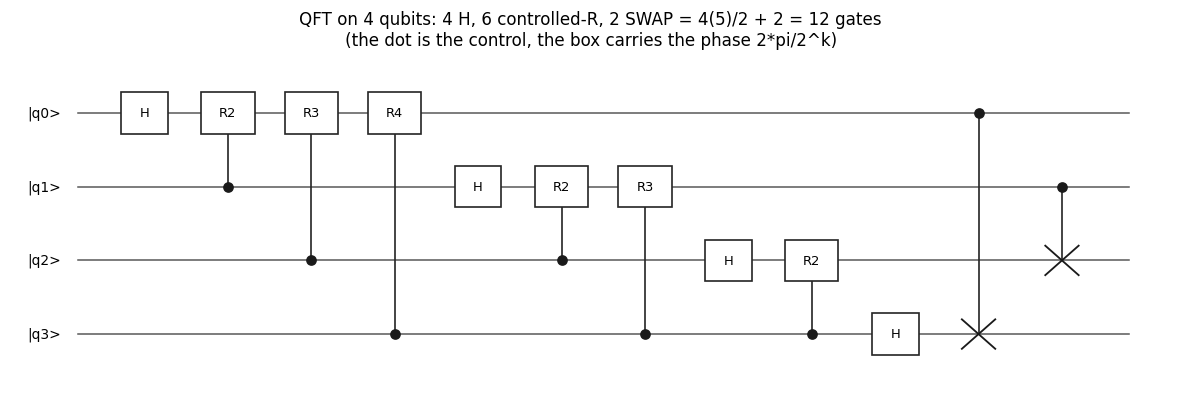

In [3]:
from matplotlib.patches import Rectangle


# Every operation in this notebook is a 4-tuple:
#   (matrix, [qubits], label, angle_scale)
# `qubits[0]` is the control for two-qubit gates, and `angle_scale` is only used by the
# noise model in Part 12 (it records how many times the base angle is amplified).
def qft_ops(n, swaps=True):
    """Textbook QFT circuit: for p in 0..n-1, H on p then cR_{q-p+1} from each q>p."""
    ops = []
    for p in range(n):
        ops.append((H, [p], "H", 0.0))
        for q in range(p + 1, n):
            k = q - p + 1
            ops.append((controlled(R(k)), [q, p], "R%d" % k, 1.0))
    if swaps:
        for p in range(n // 2):
            ops.append((SWAP, [p, n - 1 - p], "SWAP", 0.0))
    return ops


def inverse_ops(ops):
    """Run a circuit backwards with every gate daggered -- that is the inverse unitary."""
    return [(U.conj().T, tg, label + "^dag", lvl) for (U, tg, label, lvl) in reversed(ops)]


def iqft_ops(n, swaps=True):
    return inverse_ops(qft_ops(n, swaps))


def run_ops(psi, ops, n):
    for U, tg, label, lvl in ops:
        psi = apply_unitary(psi, U, tg, n)
    return psi


def circuit_matrix(ops, n):
    """Slow, honest way: push every basis state through the circuit, take the columns."""
    return np.stack([run_ops(ket(j, n), ops, n) for j in range(2 ** n)], axis=1)


def circuit_depth(ops):
    """Greedy layering: a gate's layer is one past the busiest qubit it touches."""
    layer_of = {}
    for U, tg, label, lvl in ops:
        d = 1 + max([layer_of.get(q, 0) for q in tg])
        for q in tg:
            layer_of[q] = d
    return max(layer_of.values()) if layer_of else 0


def gate_census(ops):
    one = sum(1 for U, tg, lab, lvl in ops if len(tg) == 1)
    two = len(ops) - one
    swap = sum(1 for U, tg, lab, lvl in ops if lab.startswith("SWAP"))
    rot = sum(1 for U, tg, lab, lvl in ops if len(tg) == 2 and not lab.startswith("SWAP"))
    return one, rot, swap


print("circuit vs matrix, gate count vs n(n+1)/2, depth vs 2n")
for n in range(2, 7):
    ops = qft_ops(n)
    M = circuit_matrix(ops, n)
    F = qft_matrix(n)
    one, rot, swap = gate_census(ops)
    print("  n=%d  gates %3d = %d H + %d cR + %d SWAP   formula n(n+1)/2+floor(n/2) = %3d"
          "   depth %2d   max|circuit - matrix| %.2e"
          % (n, len(ops), one, rot, swap, n * (n + 1) // 2 + n // 2,
             circuit_depth(ops), np.max(np.abs(M - F))))

n = 4
ops = qft_ops(n)
print("\nthe %d gates of QFT(4), in order:" % len(ops))
for i, (U, tg, label, lvl) in enumerate(ops):
    if len(tg) == 1:
        print("  %2d)  H  on q%d" % (i, tg[0]))
    elif label.startswith("SWAP"):
        print("  %2d)  SWAP  q%d <-> q%d" % (i, tg[0], tg[1]))
    else:
        theta = 2 * math.pi / 2 ** int(label[1:])
        print("  %2d)  cR_%s  control q%d -> target q%d   (phase %.4f rad = pi/%d)"
              % (i, label[1:], tg[0], tg[1], theta, 2 ** (int(label[1:]) - 1)))


def draw_circuit(ops, n, title, figsize=None):
    """Wire diagram in our convention: q0 on top, controls above their targets."""
    fig, ax = plt.subplots(figsize=figsize or (0.72 * len(ops) + 2.2, 0.62 * n + 1.3))
    xs = np.arange(len(ops))
    for q in range(n):
        y = n - 1 - q
        ax.plot([-0.8, len(ops) - 0.2], [y, y], color="0.35", lw=1.0, zorder=1)
        ax.text(-1.0, y, "|q%d>" % q, ha="right", va="center", fontsize=9)
    for i, (U, tg, label, lvl) in enumerate(ops):
        ys = [n - 1 - q for q in tg]
        if len(tg) == 1:
            ax.add_patch(Rectangle((i - 0.28, ys[0] - 0.28), 0.56, 0.56, facecolor="white",
                                   edgecolor="0.15", lw=1.1, zorder=3))
            ax.text(i, ys[0], label, ha="center", va="center", fontsize=8.5, zorder=4)
        else:
            ax.plot([i, i], ys, color="0.15", lw=1.1, zorder=2)
            ax.plot(i, ys[0], "o", ms=6.0, color="0.1", zorder=4)
            if label.startswith("SWAP"):
                for dy in (-0.2, 0.2):
                    ax.plot([i - 0.2, i + 0.2], [ys[1] + dy, ys[1] - dy], color="0.1",
                            lw=1.2, zorder=4)
            else:
                ax.add_patch(Rectangle((i - 0.32, ys[1] - 0.28), 0.64, 0.56,
                                       facecolor="white", edgecolor="0.15", lw=1.1, zorder=3))
                ax.text(i, ys[1], label, ha="center", va="center", fontsize=8.5, zorder=4)
    ax.set_xlim(-1.6, len(ops) + 0.3)
    ax.set_ylim(-0.8, n - 0.2)
    ax.set_axis_off()
    ax.set_title(title, fontsize=11)
    fig.tight_layout()
    return fig


_ = draw_circuit(qft_ops(4), 4,
                 "QFT on 4 qubits: 4 H, 6 controlled-R, 2 SWAP = 4(5)/2 + 2 = 12 gates\n"
                 "(the dot is the control, the box carries the phase 2*pi/2^k)")
plt.show()


## Part 3 -- bit reversal: the trap every QFT implementation falls into

Look again at the circuit in Part 2. Wire $q_0$ receives a Hadamard first and then
*kicks* from every other wire; wire $q_{n-1}$ receives its Hadamard last and only one
kick. So the binary fraction that comes out on wire $p$ is carried in the order
$(\text{bit for }2^{-1}, \text{bit for }2^{-2},\dots)$ -- but the circuit *emits* those
bits with the weights attached in the opposite order. The exact statement:

$$\text{QFT circuit without the final SWAPs} \;=\; P\,F,\qquad
P_{j,k} = [j = \operatorname{rev}(k)],$$

where $\operatorname{rev}$ flips the $n$ bits of the index. Amplitudes come out at
bit-reversed positions, and $P$ is its own inverse so a layer of $\lfloor n/2\rfloor$
SWAPs ($q_0\leftrightarrow q_{n-1}$, $q_1\leftrightarrow q_{n-2}$, ...) repairs it.

This is not a cosmetic detail: it silently *permutes the meaning of every measured
bitstring*. In Shor's algorithm the permutation is a bijection, so it is harmless (you
just read the answer through the flip). In QPE it is fatal, because the classical
post-processing assumes the bit adjacent to the eigenvalue register carries $2^{-1}$
-- and the semiclassical version in Part 11 has to be written with that in mind.

We verify it two ways: by printing the amplitudes for two inputs (a $\delta$ function
and a single basis state, where the phase ramp is visible) and by checking the matrix
identity $M_{\text{no SWAPs}} = P F$.


matrix identity for n=4:  M_noSWAP == P @ F : True |  == F @ P : False |  M_SWAP == F : True
P is a genuine permutation: P @ P == I True , rows sum to 1 True

input |0>  (a delta at index 0, which is its own bit reversal)
   no SWAPs   magnitudes: [0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25
 0.25 0.25]
   with SWAPs magnitudes: [0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25
 0.25 0.25]

input |1> = |0001>  (q3 set): the output is a flat magnitude with a linear phase ramp
   no SWAPs   |amp| = [0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25
 0.25 0.25]
              phase (turns of 2*pi) at k=0..15: [0.    0.5   0.25  0.75  0.125 0.625 0.375 0.875 0.062 0.562 0.312 0.812
 0.188 0.688 0.438 0.938]
   no SWAPs   equals the clean ramp 2*pi*k/16 : False
   with SWAPs |amp| = [0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25
 0.25 0.25]
              phase (turns of 2*pi) at k=0..15: [0.    0.062 0

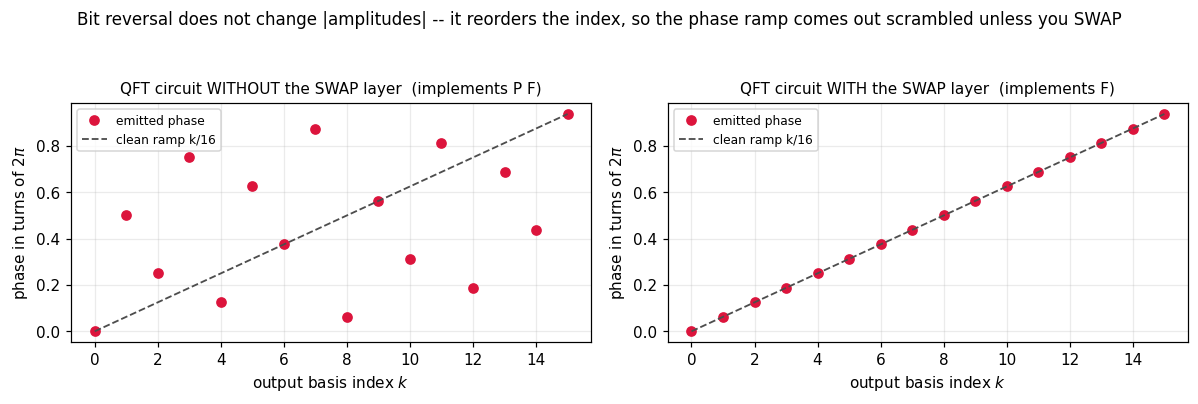

In [4]:
def bit_reverse_matrix(n):
    """The permutation P that flips all n bits of the index."""
    P = np.zeros((2 ** n, 2 ** n), dtype=complex)
    perm = bit_reverse_perm(n)
    P[np.arange(2 ** n), perm] = 1.0
    return P


n = 4
F = qft_matrix(n)
M_swap = circuit_matrix(qft_ops(n, swaps=True), n)
M_raw = circuit_matrix(qft_ops(n, swaps=False), n)
P = bit_reverse_matrix(n)

print("matrix identity for n=%d:  M_noSWAP == P @ F : %s |  == F @ P : %s |  M_SWAP == F : %s"
      % (n, np.allclose(M_raw, P @ F, atol=1e-12), np.allclose(M_raw, F @ P, atol=1e-12),
         np.allclose(M_swap, F, atol=1e-12)))
print("P is a genuine permutation: P @ P == I %s , rows sum to 1 %s"
      % (np.allclose(P @ P, np.eye(2 ** n)), np.allclose(P.sum(axis=1), np.ones(2 ** n))))

print("\ninput |0>  (a delta at index 0, which is its own bit reversal)")
for label, M in (("no SWAPs", M_raw), ("with SWAPs", M_swap)):
    v = M @ ket(0, n)
    print("   %-10s magnitudes: %s" % (label, np.round(np.abs(v), 4)))

print("\ninput |1> = |0001>  (q3 set): the output is a flat magnitude with a linear phase ramp")
for label, M in (("no SWAPs", M_raw), ("with SWAPs", M_swap)):
    v = M @ ket(1, n)
    turns = phase_turns(v)
    print("   %-10s |amp| = %s" % (label, np.round(np.abs(v), 4)))
    print("   %-10s phase (turns of 2*pi) at k=0..15: %s" % ("", np.round(turns, 3)))
    ramp = (np.arange(2 ** n) / 2 ** n) % 1.0
    print("   %-10s equals the clean ramp 2*pi*k/16 : %s"
          % (label, np.allclose(turns, ramp, atol=1e-12)))

print("\ninput |5> = |0101>: where does the single non-flat thing go? amplitude magnitudes are")
print("   still flat, so instead look at the *index map* the raw circuit applies:")
print("   k      bin(k)   rev(k)   |M_raw|0101>|[k] vs |F|0101>|[rev(k)]")
v_raw, v_std = M_raw @ ket(5, n), F @ ket(5, n)
for k in range(2 ** n):
    print("   %2d   %s   %s   %.6f   %.6f"
          % (k, format(k, "04b"), format(bit_reverse_index(k, n), "04b"),
             abs(v_raw[k]), abs(v_std[bit_reverse_index(k, n)])))
print("   matched to 1e-15: %s" % np.allclose(v_raw, v_std[bit_reverse_perm(n)], atol=1e-15))

fig, axes = plt.subplots(1, 2, figsize=(11.0, 3.7))
for ax, (label, M) in zip(axes, (("QFT circuit WITHOUT the SWAP layer  (implements P F)", M_raw),
                                 ("QFT circuit WITH the SWAP layer  (implements F)", M_swap))):
    v = M @ ket(1, n)
    ax.plot(np.arange(16), phase_turns(v), "o", ms=6, color="crimson", label="emitted phase")
    ax.plot(np.arange(16) + 0.0, np.arange(16) / 16.0, "--", lw=1.2, color="0.3",
            label="clean ramp k/16")
    ax.set_xlabel("output basis index $k$")
    ax.set_ylabel("phase in turns of $2\\pi$")
    ax.set_title(label, fontsize=10)
    ax.set_xticks(range(0, 16, 2))
    ax.legend(loc="upper left", fontsize=8)
fig.suptitle("Bit reversal does not change |amplitudes| -- it reorders the index, "
             "so the phase ramp comes out scrambled unless you SWAP", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()


## Part 4 -- the inverse QFT, and the round-trip identity

QPE is "QFT followed by readout", but the register it reads out is Fourier-encoded, so
what QPE actually applies is $F^\dagger$. There are two ways to get it:

1. **Conjugate transpose the matrix**: $F^{-1} = F^\dagger$, entries $F^\dagger[j,k] =
e^{-2\pi i jk/N}/\sqrt N$. Cheap, and only available because we wrote the matrix down.
2. **Run the circuit backwards**: reverse the gate list and dagger every gate. A
   Hadamard is its own inverse; $R_k^\dagger = \operatorname{diag}(1, e^{-2\pi i/2^k})$;
   a SWAP is its own inverse. So $\text{IQFT} = $ the same drawing, read right to left,
   with every rotation angle negated.

These must agree, and the round trip $F^\dagger F$ must be the identity to machine
precision on *any* state, not just basis states. With $N = 2^n$ complex amplitudes the
best you can hope for is a relative error of order $N\epsilon_{\text{machine}} \approx
2^n \cdot 2.2\times10^{-16}$, so a max-abs error below $10^{-14}$ at $n\le5$ is the
numerics working correctly -- not a bug, not luck.

We also check the property that makes QPE's Fourier step invertible in the first place:
the DFT matrix is symmetric, $F = F^{\mathsf T}$, which is why the same circuit
topology works in both directions.


In [5]:
print("two ways to build the inverse QFT, on the same qubits")
for n in (2, 3, 4, 5):
    N = 2 ** n
    F = qft_matrix(n)
    dag_from_matrix = F.conj().T
    dag_from_circuit = circuit_matrix(iqft_ops(n), n)
    print("  n=%d  circuit-IQFT == F^dag : %s   max diff %.2e  |  F == F^T : %s  |  "
          "||F^dag F - I||_max %.2e"
          % (n, np.allclose(dag_from_circuit, dag_from_matrix, atol=1e-12),
             np.max(np.abs(dag_from_circuit - dag_from_matrix)), np.allclose(F, F.T, atol=1e-12),
             np.max(np.abs(dag_from_matrix @ F - np.eye(N)))))

print("\nround trip on random states (seeded): max | F^dag F psi - psi |")
for n in (2, 3, 4, 5):
    worst = 0.0
    for _ in range(20):
        psi = random_state(2 ** n, rng)
        out = run_ops(run_ops(psi, qft_ops(n), n), iqft_ops(n), n)
        worst = max(worst, np.max(np.abs(out - psi)))
    print("  n=%d  N=%3d qubits=%d : worst %.2e   (threshold 1e-14 : %s)"
          % (n, 2 ** n, n, worst, worst < 1e-14))

psi = random_state(16, rng)
after_qft = run_ops(psi, qft_ops(4), 4)
back = run_ops(after_qft, iqft_ops(4), 4)
print("\na single state, end to end (n=4):")
print("  || psi || = %.12f ,  overlap <psi|round-trip|psi> = %.12f (global phase removed)"
      % (np.linalg.norm(psi), ray_overlap(psi, back)))
print("  fidelity lost to floating point: %.2e" % abs(1.0 - ray_overlap(psi, back) ** 2))


two ways to build the inverse QFT, on the same qubits
  n=2  circuit-IQFT == F^dag : True   max diff 2.69e-16  |  F == F^T : True  |  ||F^dag F - I||_max 1.17e-16
  n=3  circuit-IQFT == F^dag : True   max diff 1.43e-15  |  F == F^T : True  |  ||F^dag F - I||_max 7.06e-16
  n=4  circuit-IQFT == F^dag : True   max diff 2.27e-15  |  F == F^T : True  |  ||F^dag F - I||_max 1.87e-15
  n=5  circuit-IQFT == F^dag : True   max diff 3.50e-15  |  F == F^T : True  |  ||F^dag F - I||_max 2.45e-15

round trip on random states (seeded): max | F^dag F psi - psi |
  n=2  N=  4 qubits=2 : worst 4.00e-16   (threshold 1e-14 : True)
  n=3  N=  8 qubits=3 : worst 4.45e-16   (threshold 1e-14 : True)
  n=4  N= 16 qubits=4 : worst 4.74e-16   (threshold 1e-14 : True)
  n=5  N= 32 qubits=5 : worst 4.53e-16   (threshold 1e-14 : True)

a single state, end to end (n=4):
  || psi || = 1.000000000000 ,  overlap <psi|round-trip|psi> = 1.000000000000 (global phase removed)
  fidelity lost to floating point: 4.44e-16


## Part 5 -- approximate QFT (Coppersmith): trading gates for precision

The controlled rotations with large $k$ have tiny angles: $R_k$ differs from the
identity by $2\sin(\pi/2^k) \approx 2\pi/2^k$. Once $k$ is bigger than the number of
bits you can actually resolve, that difference is below anything the readout can see --
so **delete every controlled rotation with $k > K$** and set $\varepsilon = 2^{-K}$. The
circuit then costs

$$n \text{ Hadamards } + \sum_{k=2}^{K}(n-k+1) \text{ rotations } + \lfloor n/2\rfloor
\text{ SWAPs } \;=\; O(nK)$$

gates instead of $O(n^2)$. To hit a target accuracy $\varepsilon$ you need
$K \gtrsim \log_2(2\pi n/\varepsilon)$, hence $O\!\left(n\log(n/\varepsilon)\right)$
gates: **polylogarithmic in $1/\varepsilon$ for a transform of a $2^n$-dimensional
space.** This is the version used in Shor implementations, and it is why the QFT is
called cheap even though the exact circuit has $\binom{n+1}{2}$ rotations.

The bound we verify below is the telescoping one. Write $F$ as the exact circuit and
$F_K$ as the truncated circuit; the two differ only in the dropped gates, and each
dropped gate costs at most $\lVert I - \mathrm{cR}_k\rVert = 2\sin(\pi/2^k)$ in
operator norm, appearing $n-k+1$ times:

$$\lVert F - F_K\rVert \;\le\; \sum_{k>K}(n-k+1)\,2\sin(\pi/2^k)
\;\le\; 2\pi\,(n-K)\,2^{-K},
\qquad 1-\mathcal F \;\le\; \lVert F-F_K\rVert ,$$

where $\mathcal F = |\langle F, F_K\rangle_{\text{HS}}|/\lVert F\rVert\,\lVert F_K\rVert$
is the ray overlap of the two matrices (a unitary-vs-unitary version of state
fidelity). The first inequality is what a naive "sum the angles" argument gives; note
how much tighter it is than the smooth closed form.


K = n means nothing was dropped: check the formulas agree with the exact circuit
  n=5  formula 17  counted 17  exact 17  |  CR formula 10  counted 10
  n=8  formula 40  counted 40  exact 40  |  CR formula 28  counted 28

n = 8 : what truncation actually costs, and how good the bound is
  K  eps=2^-K   gates  exact  depth  ||F-F_K||   tight bound   smooth bound   1-fidelity
  1   0.50000     12      40      2    1.99961    17.64385      21.99115    0.946335
  2   0.25000     19      40     16    1.99995     7.74436       9.42478    0.541452
  3   0.12500     25      40     16    1.98348     3.15215       3.92699    0.147483
  4   0.06250     30      40     16    1.13146     1.20125       1.57080    0.029098
  5   0.03125     34      40     16    0.41422     0.41711       0.58905    0.004863
  6   0.01562     37      40     16    0.12264     0.12271       0.19635    0.000659
  7   0.00781     39      40     16    0.02454     0.02454       0.04909    0.000056
  8   0.00391     40      40

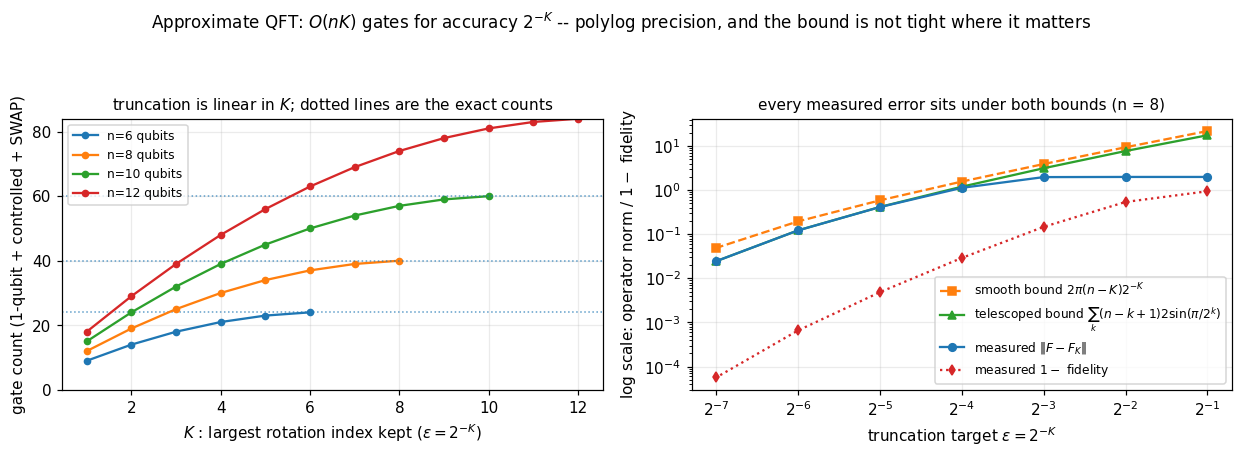

In [6]:
def approx_qft_ops(n, K, swaps=True):
    """QFT circuit with every controlled-R_k dropped for k > K.  eps := 2**-K."""
    ops = []
    for p in range(n):
        ops.append((H, [p], "H", 0.0))
        for q in range(p + 1, n):
            k = q - p + 1
            if k <= K:
                ops.append((controlled(R(k)), [q, p], "R%d" % k, 1.0))
    if swaps:
        for p in range(n // 2):
            ops.append((SWAP, [p, n - 1 - p], "SWAP", 0.0))
    return ops


def approx_gate_count(n, K):
    """Closed form of n + sum_{k=2..K}(n-k+1) + floor(n/2)."""
    kept = sum(n - k + 1 for k in range(2, K + 1))
    return n + kept + n // 2, kept


def approx_bound(n, K):
    """Sum of ||I - cR_k|| over the dropped gates, and its smooth relaxation."""
    tight = sum((n - k + 1) * 2.0 * abs(math.sin(math.pi / 2 ** k)) for k in range(K + 1, n + 1))
    closed = 2.0 * math.pi * max(n - K, 0) * 2.0 ** -K
    return tight, closed


print("K = n means nothing was dropped: check the formulas agree with the exact circuit")
for n in (5, 8):
    total, kept = approx_gate_count(n, n)
    ops = approx_qft_ops(n, n)
    print("  n=%d  formula %d  counted %d  exact %d  |  CR formula %d  counted %d"
          % (n, total, len(ops), len(qft_ops(n)), kept,
             sum(1 for U, tg, lab, lvl in ops if len(tg) == 2 and not lab.startswith("SWAP"))))

print("\nn = 8 : what truncation actually costs, and how good the bound is")
n = 8
F = qft_matrix(n)
print("  K  eps=2^-K   gates  exact  depth  ||F-F_K||   tight bound   smooth bound   1-fidelity")
for K in range(1, n + 1):
    ops = approx_qft_ops(n, K)
    M = circuit_matrix(ops, n)
    opnorm = np.linalg.norm(F - M, 2)
    tight, closed = approx_bound(n, K)
    fid = ray_overlap(F.ravel(), M.ravel())
    print("  %d  %8.5f %6d %7d %6d %10.5f %11.5f %13.5f %11.6f"
          % (K, 2.0 ** -K, len(ops), n * (n + 1) // 2 + n // 2, circuit_depth(ops),
             opnorm, tight, closed, max(1.0 - fid, 0.0)))
    assert opnorm <= tight + 1e-12 and tight <= closed + 1e-12 and max(1.0 - fid, 0.0) <= opnorm + 1e-12

print("\nwhat the counting means at scale (formula only -- we are not simulating 1000 qubits)")
print("  n       eps=1e-3: K  gates   exact     eps=1e-9: K  gates   exact")
for n in (20, 50, 100, 250, 1000):
    exact = n * (n + 1) // 2 + n // 2
    cells = []
    for eps in (1e-3, 1e-9):
        K = int(math.ceil(math.log2(2.0 * math.pi * n / eps)))
        Ke = min(K, n)
        g, _ = approx_gate_count(n, Ke)
        cells.append((K, Ke, g))
    print("  %4d    " % n + "".join("  %2d %s %8d %8d " % (K, "(trunc)" if Ke < n else "(full)", g, exact)
                                    for K, Ke, g in cells))

fig, axes = plt.subplots(1, 2, figsize=(11.4, 4.2))
ax = axes[0]
for n in (6, 8, 10, 12):
    Ks = np.arange(1, n + 1)
    ax.plot(Ks, [len(approx_qft_ops(n, K)) for K in Ks], "o-", ms=4, label="n=%d qubits" % n)
    ax.axhline(n * (n + 1) // 2 + n // 2, ls=":", lw=1.0, alpha=0.7)
ax.set_xlabel("$K$ : largest rotation index kept ($\\varepsilon = 2^{-K}$)")
ax.set_ylabel("gate count (1-qubit + controlled + SWAP)")
ax.set_title("truncation is linear in $K$; dotted lines are the exact counts", fontsize=10)
ax.set_ylim(0, 84)
ax.legend(fontsize=8, loc="upper left")
ax = axes[1]
n = 8
Ks = np.arange(1, n)
errs, tight, smooth, fids = [], [], [], []
for K in Ks:
    M = circuit_matrix(approx_qft_ops(n, K), n)
    t, c = approx_bound(n, K)
    errs.append(np.linalg.norm(F - M, 2))
    tight.append(t)
    smooth.append(c)
    fids.append(max(1.0 - ray_overlap(F.ravel(), M.ravel()), 0.0))
eps = 2.0 ** -Ks
ax.plot(eps, smooth, "s--", ms=5, color="tab:orange", label="smooth bound $2\\pi(n-K)2^{-K}$")
ax.plot(eps, tight, "^-", ms=5, color="tab:green", label="telescoped bound $\\sum_k (n-k+1)2\\sin(\\pi/2^k)$")
ax.plot(eps, errs, "o-", ms=5, color="tab:blue", label="measured $\\| F-F_K\\|$")
ax.plot(eps, fids, "d:", ms=5, color="tab:red", label="measured $1-$ fidelity")
ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.set_xlabel("truncation target $\\varepsilon = 2^{-K}$")
ax.set_ylabel("log scale: operator norm / $1-$ fidelity")
ax.set_title("every measured error sits under both bounds (n = 8)", fontsize=10)
ax.legend(fontsize=8, loc="lower right")
fig.suptitle("Approximate QFT: $O(nK)$ gates for accuracy $2^{-K}$ -- "
             "polylog precision, and the bound is not tight where it matters", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()


## Part 6 -- QFT versus the classical FFT: same matrix, different world

The QFT matrix *is* the DFT matrix, and the circuit factorisation above *is* the
Cooley--Tukey decomposition of the twiddle factors. So why does everybody say the QFT is
"the exponential speed-up of the FFT"? Because the two procedures do not live in the
same world:

| | classical FFT | quantum QFT |
|---|---|---|
| object it acts on | a vector of $N$ **numbers you already have** | the $N$ **amplitudes of a state** |
| cost | $O(N\log N)$ arithmetic ops | $O(n^{2})$ gates $=O(n\log n)$ approximate, $N=2^n$ |
| input | you may choose $x$ freely | you must *prepare* $\sum_x x_i\lvert i\rangle$; arbitrary preparation costs $\Omega(N)$ gates |
| output | all $N$ numbers, exactly | one bitstring. Measuring gives $\approx\log_2 N$ bits and destroys the state |
| what you can read | every frequency component | **one** sample from $\lvert\hat\phi_k\rvert^2$ -- a phase, not a spectrum |
| re-use | unlimited | you do not get the state back |

The honest summary: the QFT is not a faster FFT. It cannot even *contain* your data
unless you paid to prepare it, and it will not hand you the Fourier transform -- it
hands you one index drawn from the squared transform. Its power is that it converts a
**period or a phase that already exists in the state** into a peak you can measure.
Parts 7 and 8 are exactly that statement, made twice: once for a periodic state (the
seed of Shor) and once for an eigenstate (QPE, the engine of Shor, order-finding,
Hamiltonian eigenvalues, quantum phase estimation in every application).

Below we implement a real radix-2 FFT ourselves and check it against the matrix we built,
including the bit-reversal permutation -- because an iterative FFT shuffles its input
into bit-reversed order for exactly the reason Part 3 exists.


our FFT against the signal-processing DFT and against our own QFT matrix
The butterfly multiplies by w = exp(-2 pi i / N); F[j,k] carries exp(+2 pi i jk / N).
Opposite phase sign and no 1/sqrt(N): the FFT computes the UNNORMALISED INVERSE QFT.
Both differences must be undone before the two can be compared -- column 3 shows what
happens if only the normalisation is fixed and the sign is ignored.
  N=2^1=   2  max|ours - np.fft.fft| 0.00e+00   max|ours/sqrt(N) - F^dag x| 1.11e-16   max|ours/sqrt(N) - F x| 1.24e-16
  N=2^2=   4  max|ours - np.fft.fft| 0.00e+00   max|ours/sqrt(N) - F^dag x| 1.14e-16   max|ours/sqrt(N) - F x| 4.36e-01
  N=2^3=   8  max|ours - np.fft.fft| 2.29e-16   max|ours/sqrt(N) - F^dag x| 6.16e-16   max|ours/sqrt(N) - F x| 6.69e-01
  N=2^4=  16  max|ours - np.fft.fft| 2.29e-16   max|ours/sqrt(N) - F^dag x| 1.09e-15   max|ours/sqrt(N) - F x| 5.71e-01
  N=2^5=  32  max|ours - np.fft.fft| 5.66e-16   max|ours/sqrt(N) - F^dag x| 1.46e-15   max|ours/sqrt(N) - F x| 4.73e-01
  

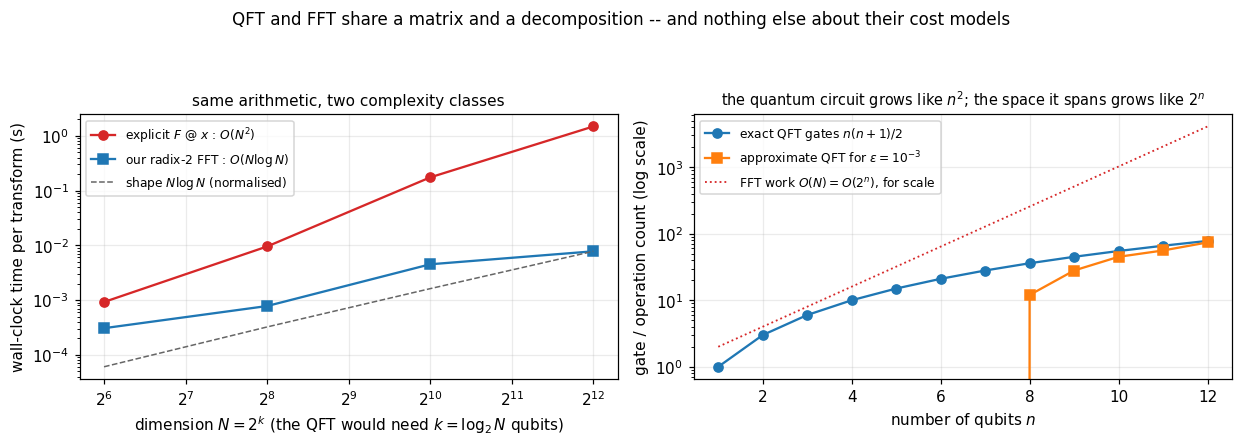

In [7]:
import time


def fft_radix2(z):
    """In-place iterative radix-2 Cooley-Tukey FFT, written from scratch (no scipy/numpy.fft)."""
    z = np.asarray(z, dtype=complex).copy()
    n = z.size
    if n & (n - 1):
        raise ValueError("length must be a power of two")
    bits = n.bit_length() - 1
    z = z[bit_reverse_perm(bits)]                     # the same permutation as Part 3
    length = 2
    while length <= n:
        half = length // 2
        w = np.exp(-2.0j * np.pi * np.arange(half) / length)
        blocks = z.reshape(-1, length)
        lo = blocks[:, :half].copy()                  # copy: blocks is a view of z
        hi = w * blocks[:, half:]
        blocks[:, :half] = lo + hi
        blocks[:, half:] = lo - hi
        length *= 2
    return z


print("our FFT against the signal-processing DFT and against our own QFT matrix")
print("The butterfly multiplies by w = exp(-2 pi i / N); F[j,k] carries exp(+2 pi i jk / N).")
print("Opposite phase sign and no 1/sqrt(N): the FFT computes the UNNORMALISED INVERSE QFT.")
print("Both differences must be undone before the two can be compared -- column 3 shows what")
print("happens if only the normalisation is fixed and the sign is ignored.")
for bits in range(1, 9):
    N = 2 ** bits
    x = random_state(N, rng)
    ours = fft_radix2(x)
    ref = np.fft.fft(x)                              # referee for the butterfly itself
    inv_qft = dft_matrix(N).conj() @ x               # F^dagger |x>, F symmetric so conj(F) works
    print("  N=2^%d=%4d  max|ours - np.fft.fft| %.2e   max|ours/sqrt(N) - F^dag x| %.2e"
          "   max|ours/sqrt(N) - F x| %.2e"
          % (bits, N, np.max(np.abs(ours - ref)),
             np.max(np.abs(ours / math.sqrt(N) - inv_qft)),
             np.max(np.abs(ours / math.sqrt(N) - dft_matrix(N) @ x))))

print("\nwhy the 1/sqrt(N) and the permutation are both needed:")
x = np.arange(8, dtype=complex)
print("  fft of [0..7], first 4 entries :", np.round(fft_radix2(x)[:4], 4))
print("  in numpy.fft.fft              :", np.round(np.fft.fft(x)[:4], 4))

print("\ntiming: quadratic matrix product vs our O(N log N) FFT (seconds)")
print("   N        explicit F @ x      our fft        ratio")
timings = []
for bits in (6, 8, 10, 12):
    N = 2 ** bits
    x = random_state(N, rng)
    t0 = time.perf_counter()
    _ = dft_matrix(N) @ x
    t_matmul = time.perf_counter() - t0
    t0 = time.perf_counter()
    for _ in range(3):
        _ = fft_radix2(x)
    t_fft = (time.perf_counter() - t0) / 3.0
    timings.append((N, t_matmul, t_fft))
    print("  %7d      %11.5f %13.5f %11.1f" % (N, t_matmul, t_fft, t_matmul / max(t_fft, 1e-12)))

fig, axes = plt.subplots(1, 2, figsize=(11.4, 4.1))
ax = axes[0]
Ns = np.array([t[0] for t in timings], dtype=float)
ax.plot(Ns, [t[1] for t in timings], "o-", color="tab:red", label="explicit $F\\ @\\ x$ : $O(N^2)$")
ax.plot(Ns, [t[2] for t in timings], "s-", color="tab:blue", label="our radix-2 FFT : $O(N\\log N)$")
ax.plot(Ns, [N * math.log2(N) / (Ns[3] * math.log2(Ns[3])) * timings[3][2] for N in Ns],
        "--", lw=1.0, color="0.4", label="shape $N\\log N$ (normalised)")
ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.set_xlabel("dimension $N = 2^k$ (the QFT would need $k = \\log_2 N$ qubits)")
ax.set_ylabel("wall-clock time per transform (s)")
ax.set_title("same arithmetic, two complexity classes", fontsize=10)
ax.legend(fontsize=8, loc="upper left")
ax = axes[1]
ks = np.arange(1, 13)
ax.plot(ks, ks * (ks + 1) // 2, "o-", color="tab:blue", label="exact QFT gates $n(n+1)/2$")
ax.plot(ks, [approx_gate_count(int(n), max(int(math.ceil(math.log2(2 * math.pi * n / 1e-3))), 1))
             [0] for n in ks], "s-", color="tab:orange",
        label="approximate QFT for $\\varepsilon=10^{-3}$")
ax.plot(ks, 2.0 ** ks, ":", color="tab:red", lw=1.2, label="FFT work $O(N)=O(2^n)$, for scale")
ax.set_yscale("log")
ax.set_xlabel("number of qubits $n$")
ax.set_ylabel("gate / operation count (log scale)")
ax.set_title("the quantum circuit grows like $n^2$; the space it spans grows like $2^n$", fontsize=9.5)
ax.legend(fontsize=8, loc="upper left")
fig.suptitle("QFT and FFT share a matrix and a decomposition -- and nothing else about their cost models",
             fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()


## Part 7 -- QFT of a periodic state: the seed of Shor

Here is the "same matrix, different world" point made concrete. Take a state that is
*already* periodic -- uniform on a subgroup of $\mathbb{Z}_{2^n}$:

$$\lvert \psi_d \rangle = \frac{1}{\sqrt{N/d}}\sum_{m=0}^{N/d-1}\lvert m d\rangle ,$$

a $\delta$-comb with spacing $d$ (which must divide $N$, so $d$ is itself a power of 2
here). Apply the QFT. The amplitude at output index $k$ is

$$\hat\psi_d(k)=\frac{1}{\sqrt{ND}}\sum_{m=0}^{D-1}e^{2\pi i k m d/N},\qquad D=N/d,$$

a geometric series that collapses to zero *unless* $kd/N$ is an integer, i.e. unless
$k$ is a multiple of $D=N/d$. So

$$\Pr[k]=\begin{cases}1/d & k\equiv 0 \!\!\!\mod N/d\\[2pt] 0 & \text{otherwise.}\end{cases}$$

**A comb in one domain is a comb in the other, with reciprocal spacing, and the peak
height tells you the spacing.** Measure once and you learn $N/d$ exactly. That single
fact is the whole Fourier step of Shor's algorithm: prepare a uniform superposition over
the order-finding function, which is periodic with period $r$, and the QFT concentrates
probability onto multiples of $N/r$. One shot gives a multiple of $N/r$, and $\gcd$
post-processing plus a couple of repeats gives $r$.

We check the exact peak positions and heights, then look at the interesting failure
mode: a period that does *not* divide $N$, which is the generic case (real periods $r$
are not powers of two). Then the peaks smear into the sinc-shaped side lobes we will
meet again in Part 9.


n=4, N=16 : QFT of a uniform comb with spacing d
  d= 1  support 16 ->  1 peaks, first few [np.int64(0)]
          peak height 1.000000  (1/d = 1.000000)  ;  total probability 1.000000000000
  d= 2  support  8 ->  2 peaks, first few [np.int64(0), np.int64(8)]
          peak height 0.500000  (1/d = 0.500000)  ;  total probability 1.000000000000
  d= 4  support  4 ->  4 peaks, first few [np.int64(0), np.int64(4), np.int64(8), np.int64(12)]
          peak height 0.250000  (1/d = 0.250000)  ;  total probability 1.000000000000
  d= 8  support  2 ->  8 peaks, first few [np.int64(0), np.int64(2), np.int64(4), np.int64(6), np.int64(8), np.int64(10)]
          peak height 0.125000  (1/d = 0.125000)  ;  total probability 1.000000000000
  d=16  support  1 -> 16 peaks, first few [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
          peak height 0.062500  (1/d = 0.062500)  ;  total probability 1.000000000000

same input, the two circuit conventions of Part 3:
  wit

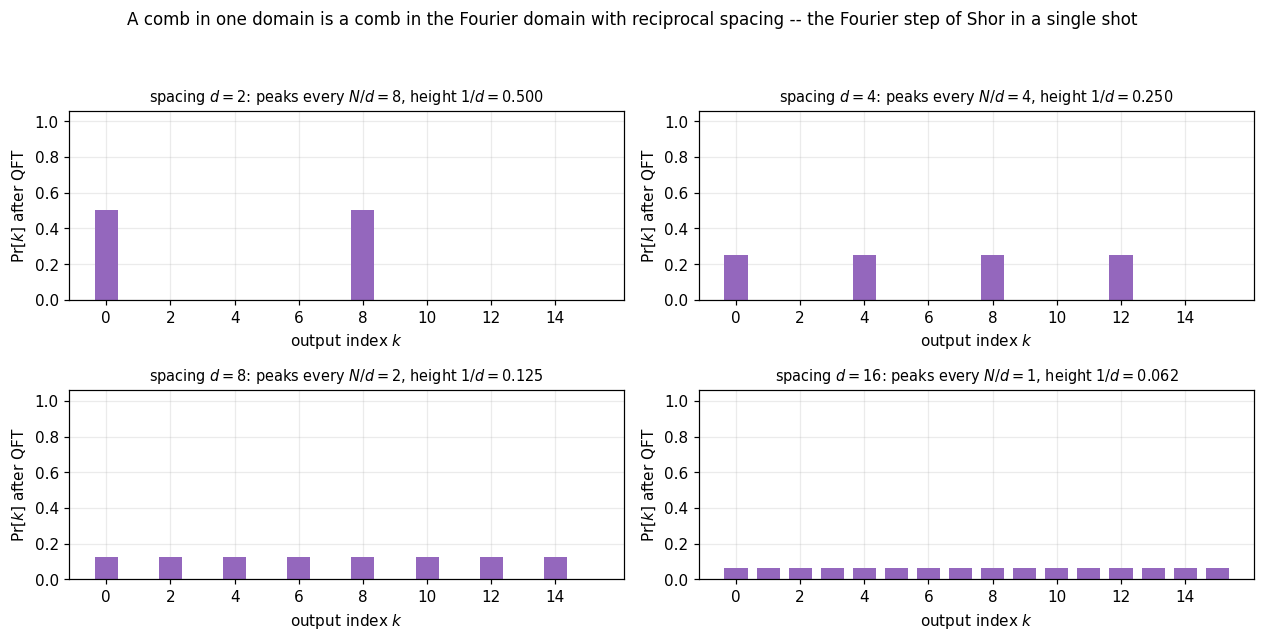

In [8]:
def comb_state(n, d):
    """Uniform state on the subgroup {0, d, 2d, ...} of Z_{2^n}; d must divide 2^n."""
    N = 2 ** n
    if N % d:
        raise ValueError("d must divide N for an exact subgroup")
    v = np.zeros(N, dtype=complex)
    v[::d] = 1.0
    return v / math.sqrt(v[::d].size)


def geometric_comb_state(n, r, terms):
    """Uniform on {0, r, 2r, ..., (terms-1)r} mod 2^n -- a period that need NOT divide N."""
    N = 2 ** n
    v = np.zeros(N, dtype=complex)
    for m in range(terms):
        v[(m * r) % N] += 1.0
    return v / np.linalg.norm(v)


n, N = 4, 16
F = qft_matrix(n)
print("n=%d, N=%d : QFT of a uniform comb with spacing d" % (n, N))
for d in (1, 2, 4, 8, 16):
    psi = comb_state(n, d)
    pr = np.abs(F @ psi) ** 2
    peaks = np.nonzero(pr > 1e-12)[0]
    support = int(np.count_nonzero(psi))
    expected = np.arange(0, N, max(N // d, 1)) if d > 1 else np.array([0])
    print("  d=%2d  support %2d -> %2d peaks, first few %s" % (d, support, peaks.size, list(peaks[:6])))
    print("          peak height %.6f  (1/d = %.6f)  ;  total probability %.12f"
          % (pr[peaks].mean(), 1.0 / d, pr.sum()))
    assert np.allclose(peaks, expected), (d, peaks, expected)
    assert np.allclose(pr[peaks], 1.0 / d, atol=1e-12)

psi4 = comb_state(n, 4)
pr4 = np.abs(F @ psi4) ** 2
out_circuit = run_ops(psi4, qft_ops(n), n)
out_raw = run_ops(psi4, qft_ops(n, swaps=False), n)
print("\nsame input, the two circuit conventions of Part 3:")
print("  with SWAPs    peaks at %s   (circuit == matrix: max amp diff %.2e)"
      % (list(np.nonzero(np.abs(out_circuit) ** 2 > 1e-12)[0]),
         np.max(np.abs(out_circuit - F @ psi4))))
print("  without SWAPs peaks at %s   = bit reversal of the above %s"
      % (list(np.nonzero(np.abs(out_raw) ** 2 > 1e-12)[0]),
         [bit_reverse_index(k, n) for k in np.nonzero(pr4 > 1e-12)[0]]))

print("\nwhat breaks the exactness: a period that is not a power of two (Shor's r never is)")
r, terms = 6, 3
psi = geometric_comb_state(n, r, terms)
pr = np.abs(F @ psi) ** 2
top = np.argsort(pr)[::-1][:5]
print("  uniform on {0,%d,%d}: strongest bins %s" % (r, 2 * r, list(top)))
print("     with P %s ; top-5 mass %.4f ; ideal peak spacing N/r = %.3f is not an integer"
      % (np.round(pr[top], 4), pr[top].sum(), N / r))
print("  so the delta-comb identity becomes a Dirichlet kernel with sinc tails -- the same")
print("  object QPE has to live with in Part 9, and the reason Shor uses continued fractions.")

fig, axes = plt.subplots(2, 2, figsize=(11.6, 5.9))
for ax, d in zip(axes.ravel(), (2, 4, 8, 16)):
    pr = np.abs(F @ comb_state(n, d)) ** 2
    ax.bar(np.arange(N), pr, width=0.72, color="tab:purple")
    ax.set_title("spacing $d=%d$: peaks every $N/d=%d$, height $1/d=%.3f$"
                 % (d, N // d, 1.0 / d), fontsize=9.5)
    ax.set_xlabel("output index $k$")
    ax.set_ylabel("$\\Pr[k]$ after QFT")
    ax.set_ylim(0, 1.06)
    ax.set_xticks(range(0, N, 2))
fig.suptitle("A comb in one domain is a comb in the Fourier domain with reciprocal spacing"
             " -- the Fourier step of Shor in a single shot", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()


## Part 8 -- quantum phase estimation, built from eigenpairs we make ourselves

Everything in this notebook so far was a means to this. Let $U\lvert u\rangle =
e^{2\pi i\phi}\lvert u\rangle$. QPE estimates $\phi\in[0,1)$ using a *counting* register
of $t$ qubits and the (unknown-eigenvector) register holding $\lvert u\rangle$:

1. prepare $\lvert 0\rangle^{\otimes t}\lvert u\rangle$,
2. Hadamard every counting qubit,
3. apply $\text{c-}U^{2^{j}}$ from counting qubit $j$ to $\lvert u\rangle$,
4. apply $F_t^{\dagger}$ to the counting register,
5. measure.

Step 3 is where the whole algorithm's power sits, and step 4 is exactly the inverse QFT
of Part 4 -- which is why bit-reversal conventions have to be nailed down before QPE can
be discussed at all. After step 3 the counting register carries the phase ramp
$2^{-1}b_0+2^{-2}b_1+\dots$ of $e^{2\pi i\phi k}$ over the integer $k$ read out of the
register (see Part 3), i.e. it is $F_t\lvert\text{binary fraction of }\phi\rangle$; the
inverse QFT un-encodes it.

**We get to choose the ground truth.** Rather than asking a black box for eigenvalues,
we build unitaries with eigenvalues we know analytically and check that QPE recovers
them. Conventions matter here, so two of them are stated up front:

* `phase_gate(theta) = diag(1, e^{i theta})` has $\phi = \theta / 2\pi$ on $\lvert 1\rangle$.
* `Rz(theta) = diag(e^{-i theta/2}, e^{+i theta/2})` is **not** a phase gate: its
  $\lvert 1\rangle$ eigenvalue is $e^{+i\theta/2}$, so $\phi = \theta / 4\pi$. Feed
  $\mathrm{R}_z$ a target $\phi$ and you must set $\theta = 4\pi\phi$. Getting this
  factor of two wrong is the single most common QPE bug; we print both.


In [9]:
def qpe_circuit(U, t, prep_ops):
    """Full QPE: counting qubits 0..t-1 (MSB-first), eigen register t..n-1 prepared by prep_ops.

    c-U^(2^j) is built by repeated matrix multiplication -- no assumptions about U.
    """
    m = int(round(math.log2(U.shape[0])))
    n = t + m
    ops = list(prep_ops)
    for p in range(t):
        ops.append((H, [p], "H", 0.0))
    for p in range(t):
        j = t - 1 - p
        Uk = np.linalg.matrix_power(U, 2 ** j)
        assert np.allclose(Uk.conj().T @ Uk, np.eye(U.shape[0]), atol=1e-12), "U must be unitary"
        ops.append((controlled(Uk), [p] + list(range(t, n)), "U^%d" % 2 ** j, float(2 ** j)))
    ops += inverse_ops(qft_ops(t))
    return ops, n


def qpe_probs(U, t, prep_ops):
    """Exact counting-register probability distribution of QPE on U (full statevector)."""
    m = int(round(math.log2(U.shape[0])))
    ops, n = qpe_circuit(U, t, prep_ops)
    v = run_ops(ket(0, n), ops, n)
    return (np.abs(v.reshape(2 ** t, 2 ** m)) ** 2).sum(axis=1)


def circ_dist(a, b):
    """Distance on the unit circle: phi is periodic with period 1, and 0.99 is CLOSE to 0."""
    d = abs(a - b) % 1.0
    return min(d, 1.0 - d)


def estimate(pr, t):
    """Most likely phase and its probability, plus the ranked top candidates."""
    order = np.argsort(pr)[::-1]
    return order[0] / 2 ** t, pr[order[0]], [(k / 2 ** t, pr[k]) for k in order[:4]]


def x_on(q):
    return (X, [q], "X", 0.0)                       # prepare |1> of eigen-register qubit q


S_gate = np.diag([1.0 + 0j, 1.0j])                                    # phi = 1/4
T_gate = np.diag([1.0 + 0j, np.exp(1.0j * math.pi / 4.0)])           # phi = 1/8
Rz_gate = lambda theta: np.diag([np.exp(-0.5j * theta), np.exp(0.5j * theta)])
CP8 = controlled(T_gate)                                              # 2-qubit U: |11> -> phi = 1/8

print("spectra read straight off the matrices we built (eigenvalues as turns of 2*pi)")
for name, U in (("S", S_gate), ("T", T_gate), ("Rz(pi/2)", Rz_gate(math.pi / 2)), ("cT", CP8)):
    vals = np.linalg.eigvals(U)
    turns = np.sort(np.angle(vals) % (2.0 * math.pi) / (2.0 * math.pi))
    print("  %-10s spectrum %s" % (name, np.round(turns, 6)))

print("\nQPE on each, with the smallest register that can represent phi exactly")
cases = (("S", S_gate, 0.25, 2, 1),
         ("T", T_gate, 0.125, 3, 1),
         ("Rz(pi/2): phi = theta/4pi = 0.125", Rz_gate(math.pi / 2), 0.125, 3, 1),
         ("Rz(1.2pi): phi = 0.3 (non-dyadic)", Rz_gate(1.2 * math.pi), 0.3, 4, 1),
         ("cT on |11> (2-qubit eigenstate)", CP8, 0.125, 3, 2))
for name, U, phi_true, t, m in cases:
    prep = [x_on(t + i) for i in range(m)]          # eigen register lives on qubits t..t+m-1
    pr = qpe_probs(U, t, prep)
    best, pbest, ranked = estimate(pr, t)
    print("  %-36s t=%d :  top estimate %.6f  (true %.6f, circular error %.2e)  P=%.6f"
          % (name, t, best, phi_true, circ_dist(best, phi_true), pbest))
    print("      runners-up %s ;  probability mass %.12f"
          % (["%.4f @ %.4f" % (k, q) for k, q in ranked[1:]], pr.sum()))

print("\nthe Rz factor-of-two trap, made explicit")
theta = math.pi / 2
print("  theta = pi/2 : phi = theta/(2*pi) = %.6f   <- what you would write if Rz were a phase gate"
      % (theta / (2 * math.pi)))
print("                 phi = theta/(4*pi) = %.6f   <- correct: Rz|1> = e^{+i theta/2} |1>"
      % (theta / (4 * math.pi)))
print("  QPE returned 0.125000 above, so the second line is the convention that governs this circuit.")
print("  to DESIGN an Rz with target phi, set theta = 4*pi*phi; for phi = 0.3 that is theta = %.6f"
      % (4 * math.pi * 0.3))


spectra read straight off the matrices we built (eigenvalues as turns of 2*pi)
  S          spectrum [0.   0.25]
  T          spectrum [0.    0.125]
  Rz(pi/2)   spectrum [0.125 0.875]
  cT         spectrum [0.    0.    0.    0.125]

QPE on each, with the smallest register that can represent phi exactly
  S                                    t=2 :  top estimate 0.250000  (true 0.250000, circular error 0.00e+00)  P=1.000000
      runners-up ['0.7500 @ 0.0000', '0.5000 @ 0.0000', '0.0000 @ 0.0000'] ;  probability mass 1.000000000000
  T                                    t=3 :  top estimate 0.125000  (true 0.125000, circular error 0.00e+00)  P=1.000000
      runners-up ['0.2500 @ 0.0000', '0.0000 @ 0.0000', '0.8750 @ 0.0000'] ;  probability mass 1.000000000000
  Rz(pi/2): phi = theta/4pi = 0.125    t=3 :  top estimate 0.125000  (true 0.125000, circular error 0.00e+00)  P=1.000000
      runners-up ['0.2500 @ 0.0000', '0.0000 @ 0.0000', '0.8750 @ 0.0000'] ;  probability mass 1.000000000000

### The two regimes of QPE output

QPE is exact in exactly one case, and it is worth being precise about which.

* **Dyadic $\phi = a/2^{m}$ with $m \le t$**: the phase ramp $e^{2\pi i\phi k}$ is
  *periodic* over the $2^t$ counting states, the inverse QFT is a perfect change of
  basis, and the output is a literal $\delta$ -- probability $1.0$ on the single
  bitstring $\operatorname{bin}_t(a\,2^{t-m})$, zero everywhere else. $t$ bits are
  enough if $\phi$ has an exact $t$-bit binary expansion. Nothing to average, nothing to
  repeat.
* **Generic $\phi$**: there is no such bitstring. The state before the inverse QFT is a
  truncated geometric series, and its transform is the **Dirichlet kernel** --
  a central peak of width $\sim1$ bin and a train of side lobes. Measurement returns a
  *sample* from that distribution, so the answer is a random $k$ with
  $\Pr[k]=\big|\langle k\rvert F_t^\dagger\,\text{ramp}\rangle\big|^2$, and the best
  single-shot probability is capped at about $0.573$ no matter how many qubits you use
  (Part 9 proves the cap and the $8/\pi^2\approx0.8106$ floor for the *error*).

This distinction is why "how accurate is QPE?" has no single answer: for a
Hamiltonian eigenvalue it is never exact, and the honest question is the probability of
landing within $2^{-m}$, which is what Part 10 measures.


DYADIC case: phi = 0.375 = 3/8 needs t = 3 bits, and gets probability 1.0 on bin 3
  t=2 : P(bin  2 = 0.500000) = 0.426776695297 ; all other bins max 4.27e-01
  t=3 : P(bin  3 = 0.375000) = 1.000000000000 ; all other bins max 2.16e-32
  t=4 : P(bin  6 = 0.375000) = 1.000000000000 ; all other bins max 8.21e-32
  t=5 : P(bin 12 = 0.375000) = 1.000000000000 ; all other bins max 3.24e-31

GENERIC case: phi = 0.4 is not dyadic -- the side lobe train
  t=4  N= 16 : top bins [(np.float64(0.375), np.float64(0.573966)), (np.float64(0.4375), np.float64(0.255753)), (np.float64(0.3125), np.float64(0.047954)), (np.float64(0.5), np.float64(0.037001))]
           nearest bin 0.375000 carries P=0.573966 ; mass beyond the two best bins: 0.170281
  t=6  N= 64 : top bins [(np.float64(0.40625), np.float64(0.57286)), (np.float64(0.390625), np.float64(0.254645)), (np.float64(0.421875), np.float64(0.046832)), (np.float64(0.375), np.float64(0.035873))]
           nearest bin 0.406250 carries P=0.572860 ; mass

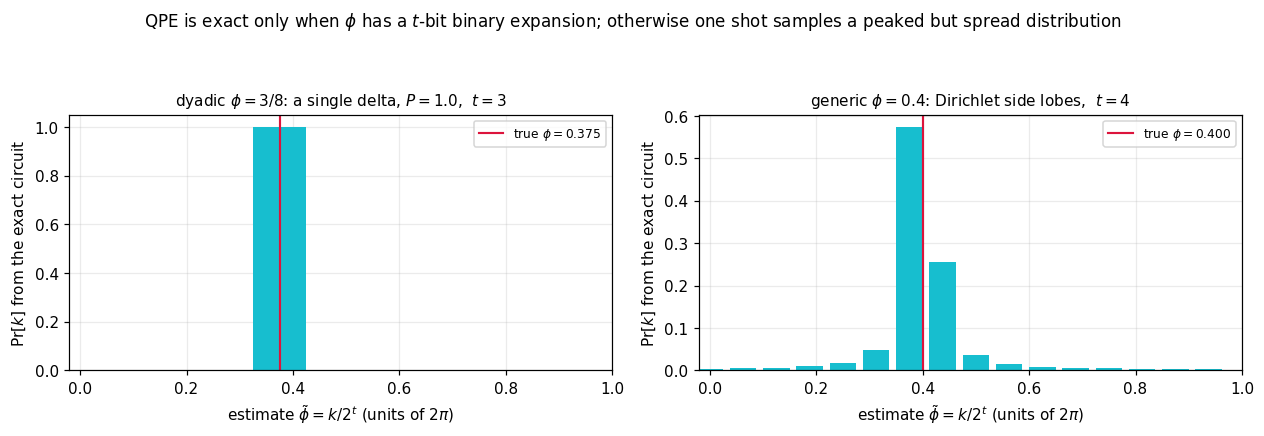


for reference, the same generic phi at higher t keeps the peak HEIGHT but shrinks the peak ERROR:
  t= 4 : peak P=0.573966 at 0.375000 ; |error| = 0.02500000
  t= 6 : peak P=0.572860 at 0.406250 ; |error| = 0.00625000  error ratio vs previous row: 4.000
  t= 8 : peak P=0.572791 at 0.398438 ; |error| = 0.00156250  error ratio vs previous row: 4.000
  t=10 : peak P=0.572787 at 0.400391 ; |error| = 0.00039062  error ratio vs previous row: 4.000
  t=12 : peak P=0.572787 at 0.399902 ; |error| = 0.00009766  error ratio vs previous row: 4.000


In [10]:
def ramp_probs(phi, t):
    """QPE distribution for the one-qubit phase gate with eigenvalue exp(2*pi*i*phi) on |1>."""
    return qpe_probs(phase_gate(2.0 * math.pi * phi), t, [x_on(t)])


print("DYADIC case: phi = 0.375 = 3/8 needs t = 3 bits, and gets probability 1.0 on bin 3")
for t in (2, 3, 4, 5):
    pr = ramp_probs(0.375, t)
    k = int(round(0.375 * 2 ** t))
    print("  t=%d : P(bin %2d = %.6f) = %.12f ; all other bins max %.2e"
          % (t, k, k / 2 ** t, pr[k], np.max(np.delete(pr, k))))

print("\nGENERIC case: phi = 0.4 is not dyadic -- the side lobe train")
for t in (4, 6, 8):
    pr = ramp_probs(0.4, t)
    order = np.argsort(pr)[::-1]
    print("  t=%d  N=%3d : top bins %s" % (t, 2 ** t, [(round(k / 2 ** t, 6), round(pr[k], 6)) for k in order[:4]]))
    print("           nearest bin %.6f carries P=%.6f ; mass beyond the two best bins: %.6f"
          % (order[0] / 2 ** t, pr[order[0]], 1.0 - pr[order[0]] - pr[order[1]]))

fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.0))
specs = [(0.375, 3, "dyadic $\\phi = 3/8$: a single delta, $P = 1.0$"),
         (0.4, 4, "generic $\\phi = 0.4$: Dirichlet side lobes")]
for ax, (phi, t, title) in zip(axes, specs):
    pr = ramp_probs(phi, t)
    ks = np.arange(2 ** t) / 2 ** t
    ax.bar(ks, pr, width=0.8 / 2 ** t, color="tab:cyan")
    ax.axvline(phi, color="crimson", lw=1.4, label="true $\\phi = %.3f$" % phi)
    ax.set_xlabel("estimate $\\tilde\\phi = k/2^t$ (units of $2\\pi$)")
    ax.set_ylabel("$\\Pr[k]$ from the exact circuit")
    ax.set_title(title + ",  $t = %d$" % t, fontsize=10)
    ax.set_xlim(-0.02, 1.0)
    ax.legend(fontsize=8, loc="upper right")
fig.suptitle("QPE is exact only when $\\phi$ has a $t$-bit binary expansion; otherwise one shot "
             "samples a peaked but spread distribution", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()

print("\nfor reference, the same generic phi at higher t keeps the peak HEIGHT but shrinks the peak ERROR:")
prev = None
for t in (4, 6, 8, 10, 12):
    pr = ramp_probs(0.4, t)
    err = circ_dist(np.argmax(pr) / 2 ** t, 0.4)
    ratio = "" if prev is None else "  error ratio vs previous row: %.3f" % (prev / err)
    print("  t=%2d : peak P=%.6f at %.6f ; |error| = %.8f%s" % (t, pr.max(), np.argmax(pr) / 2 ** t, err, ratio))
    prev = err


## Part 9 -- the Dirichlet kernel, and the $8/\pi^2$ floor

There is a closed-form answer for what QPE outputs, and we should use it instead of
pretending every distribution needs a simulation. With $N=2^t$ and
$\delta_k=\phi-k/N$,

$$\Pr[k]\;=\;\frac{1}{N^2}\Big|\sum_{x=0}^{N-1} e^{2\pi i(\phi-k/N)x}\Big|^2
=\frac{\sin^2(\pi N\delta_k)}{N^2\sin^2(\pi\delta_k)}
=\Big(\frac{\operatorname{sinc}(N\delta_k)}{\operatorname{sinc}(\delta_k)}\Big)^{2},$$

the Dirichlet kernel. (Our `np.sinc(x)` is $\sin(\pi x)/(\pi x)$, which is exactly the
normalisation this formula wants.) It explains every qualitative feature we saw in
Part 8: the peak sits on the bin nearest $\phi$ with height $\approx 0.573$, the side
lobes decay like $1/\delta^2$ -- slow, heavy tails, the Fourier transform of a
*truncated* plane wave -- and the whole thing is periodic in $\phi$ with period $1/N$,
so it is enough to scan one bin.

Two consequences are checked numerically below, and both are the reason QPE needs
repetition rather than cleverness:

* $\Pr[\text{circular error} \le 2^{-t}] \;\ge\; 8/\pi^2 = 0.810569\dots$ for **every**
  $\phi$ and every $t$. You cannot push this up by adding qubits; adding a qubit shrinks
  the *size* of the error, not the chance of being within one bin of it.
* $\Pr[\text{the single nearest bin}] \ge 4/\pi^2 = 0.40528\dots$ -- so a single shot is
  wrong more than a third of the time, worst case. The standard fix (Nielsen & Chuang
  5.21) is $t = m + \lceil\log_2(3+1/2\varepsilon)\rceil$ qubits to reach
  $\Pr[\text{error}\le 2^{-m}] \ge 1-\varepsilon$; we verify that too.


closed form vs the statevector circuit (they must agree to machine precision)
  t=2 : max |circuit - Dirichlet| over 6 phases = 9.99e-16 ; sum of Pr = 1.000000000000
  t=3 : max |circuit - Dirichlet| over 6 phases = 4.44e-16 ; sum of Pr = 1.000000000000
  t=4 : max |circuit - Dirichlet| over 6 phases = 1.17e-15 ; sum of Pr = 1.000000000000
  t=5 : max |circuit - Dirichlet| over 6 phases = 3.33e-15 ; sum of Pr = 1.000000000000
  t=6 : max |circuit - Dirichlet| over 6 phases = 6.00e-15 ; sum of Pr = 1.000000000000

worst case over a dense phi grid (2001 offsets inside one bin), per t
   t   min P(err <= 2^-t)   8/pi^2      min P(nearest bin)   4/pi^2     respects both
   1       1.000000      0.810569        0.500393        0.405285       True
   2       0.853553      0.810569        0.427181        0.405285       True
   3       0.821067      0.810569        0.410939        0.405285       True
   4       0.813179      0.810569        0.406994        0.405285       True
   5       0.8112

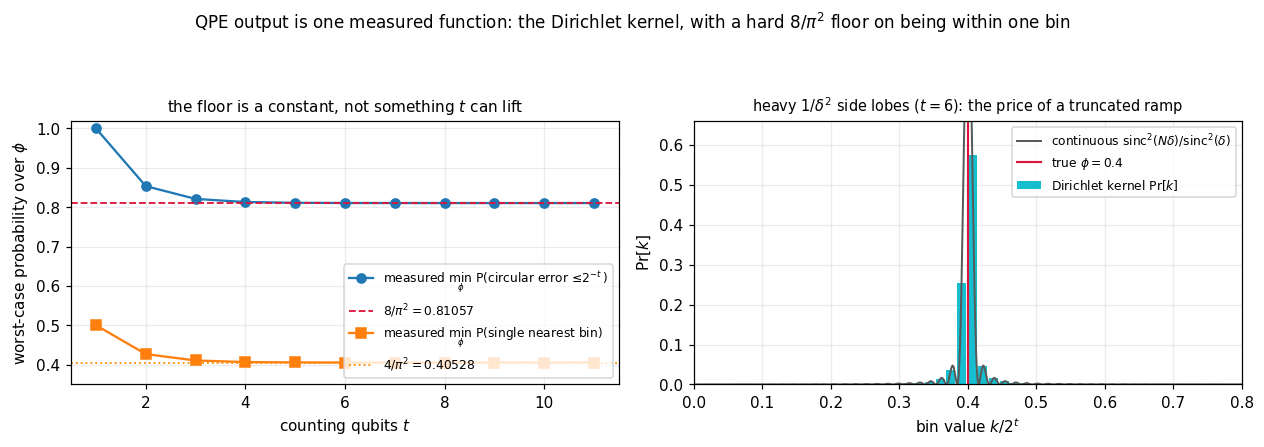

In [11]:
def dirichlet_probs(phi, t):
    """Exact QPE output distribution: Pr[k] = sinc(N*d)^2 / sinc(d)^2, d = phi - k/N."""
    N = 2 ** t
    d = phi - np.arange(N) / N
    return np.sinc(N * d) ** 2 / np.sinc(d) ** 2


def within_one_bin(phi, t):
    N = 2 ** t
    pr = dirichlet_probs(phi, t)
    d = np.abs(phi - np.arange(N) / N)
    err = np.minimum(d, 1.0 - d)
    return float(pr[err <= 2.0 ** -t + 1e-15].sum()), float(pr.max())


print("closed form vs the statevector circuit (they must agree to machine precision)")
for t in (2, 3, 4, 5, 6):
    for phi in (0.4, 0.375, 0.1, 0.62, 1.0 / 3.0, 0.999):
        a = ramp_probs(phi, t)
        b = dirichlet_probs(phi, t)
        worst = np.max(np.abs(a - b))
        assert worst < 1e-13, (t, phi, worst)
    print("  t=%d : max |circuit - Dirichlet| over 6 phases = %.2e ; sum of Pr = %.12f"
          % (t, np.max(np.abs(ramp_probs(0.4, t) - dirichlet_probs(0.4, t))), dirichlet_probs(0.4, t).sum()))

# Pr depends on phi only through its position inside a bin, so scan one bin densely.
GRID = np.linspace(0.0, 1.0, 2001, endpoint=False)
print("\nworst case over a dense phi grid (2001 offsets inside one bin), per t")
print("   t   min P(err <= 2^-t)   8/pi^2      min P(nearest bin)   4/pi^2     respects both")
rows = []
for t in range(1, 12):
    N = 2 ** t
    phis = GRID / N
    d = phis[:, None] - np.arange(N)[None, :] / N
    pr = np.sinc(N * d) ** 2 / np.sinc(d) ** 2
    err = np.minimum(np.abs(d), 1.0 - np.abs(d))
    mass = np.where(err <= 2.0 ** -t + 1e-15, pr, 0.0).sum(axis=1)
    nearest = pr[np.arange(len(phis)), np.argmin(err, axis=1)]
    rows.append((t, float(mass.min()), float(nearest.min())))
    print("  %2d       %.6f      %.6f        %.6f        %.6f       %s"
          % (t, mass.min(), 8.0 / math.pi ** 2, nearest.min(), 4.0 / math.pi ** 2,
             mass.min() >= 8.0 / math.pi ** 2 - 1e-9 and nearest.min() >= 4.0 / math.pi ** 2 - 1e-9))

print("\nNielsen & Chuang qubit budget: t = m + ceil(log2(3 + 1/(2 eps))) guarantees P(err <= 2^-m) >= 1 - eps")
for m, eps in ((3, 0.10), (3, 0.01), (5, 0.10), (5, 0.01), (7, 0.01), (4, 0.001)):
    t = m + int(math.ceil(math.log2(3.0 + 1.0 / (2.0 * eps))))
    N = 2 ** t
    phis = np.linspace(0.0, 1.0, 601, endpoint=False) / N
    d = phis[:, None] - np.arange(N)[None, :] / N
    pr = np.sinc(N * d) ** 2 / np.sinc(d) ** 2
    err = np.minimum(np.abs(d), 1.0 - np.abs(d))
    worst = np.where(err <= 2.0 ** -m, pr, 0.0).sum(axis=1).min()
    print("  m=%d bits, eps=%.3f  ->  t=%2d qubits : worst observed P = %.6f >= %.3f  %s"
          % (m, eps, t, worst, 1 - eps, worst >= 1 - eps - 1e-9))

fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.1))
ax = axes[0]
ts = [r[0] for r in rows]
ax.plot(ts, [r[1] for r in rows], "o-", color="tab:blue", label="measured $\\min_\\phi$ P(circular error $\\leq 2^{-t}$)")
ax.axhline(8.0 / math.pi ** 2, ls="--", color="crimson", lw=1.2, label="$8/\\pi^2 = 0.81057$")
ax.plot(ts, [r[2] for r in rows], "s-", color="tab:orange",
        label="measured $\\min_\\phi$ P(single nearest bin)")
ax.axhline(4.0 / math.pi ** 2, ls=":", color="darkorange", lw=1.2, label="$4/\\pi^2 = 0.40528$")
ax.set_xlabel("counting qubits $t$")
ax.set_ylabel("worst-case probability over $\\phi$")
ax.set_ylim(0.35, 1.02)
ax.set_title("the floor is a constant, not something $t$ can lift", fontsize=10)
ax.legend(fontsize=8, loc="lower right")
ax = axes[1]
t, N, phi = 6, 64, 0.4
pr = dirichlet_probs(phi, t)
kk = np.linspace(0.0, 1.0, 4001)
dd = phi - kk
ax.bar(np.arange(N) / N, pr, width=0.85 / N, color="tab:cyan", label="Dirichlet kernel $\\Pr[k]$")
ax.plot(kk, np.sinc(N * dd) ** 2 / np.sinc(dd) ** 2, lw=1.3, color="0.35",
        label="continuous $\\mathrm{sinc}^2(N\\delta)/\\mathrm{sinc}^2(\\delta)$")
ax.axvline(phi, color="crimson", lw=1.4, label="true $\\phi=0.4$")
ax.set_xlim(0, 0.8)
ax.set_ylim(0, 0.66)
ax.set_xlabel("bin value $k/2^t$")
ax.set_ylabel("$\\Pr[k]$")
ax.set_title("heavy $1/\\delta^2$ side lobes ($t=6$): the price of a truncated ramp", fontsize=9.5)
ax.legend(fontsize=8, loc="upper right")
fig.suptitle("QPE output is one measured function: the Dirichlet kernel, with a hard $8/\\pi^2$ floor "
             "on being within one bin", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()


## Part 10 -- the money analysis: what one more qubit actually buys

This is the question a practitioner asks, so we answer it with numbers rather than
asymptotics. Fix a target $\phi$ and sweep the counting register $t = 1 \dots 12$. For
each $t$ report

* $P_{\text{exact}}$ -- probability of landing on the *single nearest* bin (what a
  one-shot QPE "works" means),
* $P(\lvert\text{error}\rvert \le 2^{-t})$ -- the honest one-bin-width success rate,
* $P(\lvert\text{error}\rvert \le 2^{-m})$ for a fixed requested accuracy $m$,
* the median circular error over many $\phi$, which is the quantity that behaves nicely.

Expect three things, and we will see all three:

1. $P_{\text{exact}}$ does **not** increase with $t$. It oscillates and settles around
   $0.573$ (dyadic $\phi$ gives $1.0$). Success probability is not the currency.
2. The **error** halves per added qubit -- a slope of exactly $-1$ on a log-log plot --
   once you average over $\phi$. At one specific $\phi$ the halving is not smooth: the
   fractional parts of $2^t\phi$ follow a deterministic pattern, so a single $\phi$ can
   show a $4\times$ jump followed by no improvement at all. We plot both, because the
   second curve is the one people quietly drop from slides.
3. The **cost** is linear in $t$ in gate count and depth, but exponentially hard in the
   one place that matters: controlled-$U^{2^{t-1}}$. Depth is no excuse for stopping
   early; coherence time on $U$ is.


t   P_exact   P(<=1 bin)  P(err<=2^-4)  median err   mean err    peak bin   gates  depth  c-U apps
 1   0.9045     1.0000       0.000000      0.100000     0.128647    0.500000       4      3        1
 2   0.5920     0.8663       0.000000      0.100000     0.150266    0.500000       9      7        3
 3   0.8769     0.9335       0.876942      0.025000     0.044300    0.375000      14     10        7
 4   0.5740     0.8297       0.829719      0.025000     0.053589    0.375000      21     13       15
 5   0.8753     0.9301       0.965401      0.006250     0.014107    0.406250      28     16       31
 6   0.5729     0.8275       0.954973      0.006250     0.017370    0.406250      37     19       63
 7   0.8751     0.9299       0.991360      0.001563     0.004285    0.398438      46     22      127
 8   0.5728     0.8274       0.988695      0.001563     0.005335    0.398438      57     25      255
 9   0.8751     0.9298       0.997840      0.000391     0.001261    0.400391      68     28  

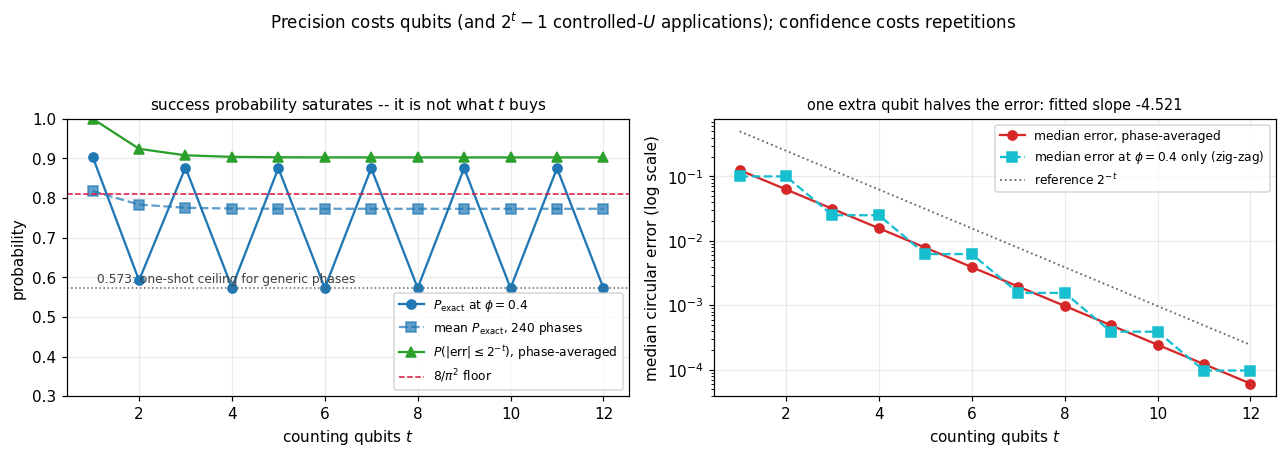


repetition versus resolution, matched on controlled-U applications (budget 4095)
  strategy                      qubits   c-U apps   P(err <= 2^-4)          resolution floor
  one run t=12                 12       4095   0.999293  (exact, single shot)   2^-12/2 = 0.000122
  15 runs of t=8                8       3825   0.717827  (mode of 15 shots, bound)   2^-8/2 = 0.001953
  63 runs of t=6                6       3969   0.878489  (mode of 63 shots, bound)   2^-6/2 = 0.007812
  127 runs of t=5               5       3937   1.000000  (mode of 127 shots, bound)   2^-5/2 = 0.015625
  273 runs of t=4               4       4095   0.993054  (mode of 273 shots, bound)   2^-4/2 = 0.031250
  depth is linear in t (t=1:3, t=4:13, t=7:22, t=10:31), so depth never justified stopping early:
  but controlled-U^(2^(t-1)) needs 2^(t-1) coherent applications -- that is the real ceiling,
  and Part 12 shows what it costs when coherence time runs out.


In [12]:
def qpe_summary(phi, t, m_request=None):
    """Everything we want to know about one QPE setting, from the exact distribution."""
    N = 2 ** t
    pr = dirichlet_probs(phi, t)
    bins = np.arange(N) / N
    err = np.minimum(np.abs(phi - bins), 1.0 - np.abs(phi - bins))
    out = {"P_exact": float(pr[np.argmin(err)]),
           "P_within_1bin": float(pr[err <= 2.0 ** -t + 1e-15].sum()),
           "peak_bin": float(bins[np.argmax(pr)])}
    if m_request is not None:
        out["P_within_2^-m"] = float(pr[err <= 2.0 ** -m_request + 1e-15].sum())
    order = np.argsort(err)
    csum = np.cumsum(pr[order])
    out["median_err"] = float(err[order][np.searchsorted(csum, 0.5)])
    out["mean_err"] = float((pr * err).sum())
    return out


def mode_success_lower_bound(p_bin, reps):
    """P(the wanted bin wins a plurality) >= P(it gets more than half the votes)."""
    if not 0.0 < p_bin < 1.0:
        return p_bin
    fail = 0.0
    for k in range(reps // 2 + 1):
        logc = math.lgamma(reps + 1) - math.lgamma(k + 1) - math.lgamma(reps - k + 1)
        fail += math.exp(logc + k * math.log(p_bin) + (reps - k) * math.log1p(-p_bin))
    return 1.0 - fail


PHI, MREQ = 0.4, 4
print("t   P_exact   P(<=1 bin)  P(err<=2^-4)  median err   mean err    peak bin   gates  depth  c-U apps")
rows = []
for t in range(1, 13):
    s = qpe_summary(PHI, t, MREQ)
    ops, _ = qpe_circuit(phase_gate(2 * math.pi * PHI), t, [x_on(t)])
    d, apps = circuit_depth(ops), 2 ** t - 1
    rows.append((t, s, len(ops), d, apps, ops))
    print("%2d   %.4f     %.4f       %.6f      %.6f     %.6f    %.6f    %4d   %4d   %6d"
          % (t, s["P_exact"], s["P_within_1bin"], s["P_within_2^-m"], s["median_err"],
             s["mean_err"], s["peak_bin"], len(ops), d, apps))

print("\nsame quantities averaged over 240 phases -- this is the smooth, honest version")
phi_grid = np.linspace(0.0, 1.0, 241, endpoint=False)[1:]
med_by_t, exact_by_t, nc_by_t, ratio_by_t = [], [], [], []
for t in range(1, 13):
    N = 2 ** t
    d = phi_grid[:, None] - np.arange(N)[None, :] / N
    pr = np.sinc(N * d) ** 2 / np.sinc(d) ** 2
    err = np.minimum(np.abs(d), 1.0 - np.abs(d))
    exact_by_t.append(float(pr[np.arange(len(phi_grid)), np.argmin(err, axis=1)].mean()))
    nc_by_t.append(float(np.where(err <= 2.0 ** -t + 1e-15, pr, 0.0).sum(axis=1).mean()))
    meds = []
    for i in range(len(phi_grid)):
        o = np.argsort(err[i])
        cs = np.cumsum(pr[i][o])
        meds.append(err[i][o][np.searchsorted(cs, 0.5)])
    med_by_t.append(float(np.median(meds)))
    ratio_by_t.append(np.nan if t == 1 else med_by_t[-2] / med_by_t[-1])
    print("  t=%2d  mean P_exact %.4f   mean P(<=1 bin) %.4f   median err %.3e   halving ratio %.3f"
          % (t, exact_by_t[-1], nc_by_t[-1], med_by_t[-1], ratio_by_t[-1]))

ts = np.arange(1, 13, dtype=float)
slope_fit = np.polyfit(np.log2(ts[2:]), np.log2(np.array(med_by_t[2:])), 1)
print("\nfitted slope of log2(median error) vs t, t>=3 : %.4f   (theory -1: one bit per qubit)"
      % slope_fit[0])
print("mean measured error-halving ratio, t>=6          : %.4f   (theory 2.0)"
      % float(np.nanmean(np.array(ratio_by_t[5:]))))

fig, axes = plt.subplots(1, 2, figsize=(11.8, 4.2))
ax = axes[0]
ax.plot(ts, [r[1]["P_exact"] for r in rows], "o-", color="tab:blue", label="$P_{\\text{exact}}$ at $\\phi=0.4$")
ax.plot(ts, exact_by_t, "s--", color="tab:blue", alpha=0.7, label="mean $P_{\\text{exact}}$, 240 phases")
ax.plot(ts, nc_by_t, "^-", color="tab:green", label="$P(|\\mathrm{err}|\\leq 2^{-t})$, phase-averaged")
ax.axhline(0.573, ls=":", color="0.4", lw=1.0)
ax.text(1.1, 0.585, "0.573: one-shot ceiling for generic phases", fontsize=8, color="0.25")
ax.axhline(8.0 / math.pi ** 2, ls="--", color="crimson", lw=1.0, label="$8/\\pi^2$ floor")
ax.set_xlabel("counting qubits $t$")
ax.set_ylabel("probability")
ax.set_ylim(0.3, 1.0)
ax.set_title("success probability saturates -- it is not what $t$ buys", fontsize=10)
ax.legend(fontsize=8, loc="lower right")
ax = axes[1]
ax.semilogy(ts, med_by_t, "o-", color="tab:red", label="median error, phase-averaged")
ax.semilogy(ts, [r[1]["median_err"] for r in rows], "s--", color="tab:cyan",
            label="median error at $\\phi=0.4$ only (zig-zag)")
ax.semilogy(ts, 2.0 ** -ts, ":", color="0.4", lw=1.2, label="reference $2^{-t}$")
ax.set_xlabel("counting qubits $t$")
ax.set_ylabel("median circular error (log scale)")
ax.set_title("one extra qubit halves the error: fitted slope %.3f" % slope_fit[0], fontsize=9.5)
ax.legend(fontsize=8, loc="upper right")
fig.suptitle("Precision costs qubits (and $2^{t}-1$ controlled-$U$ applications); confidence costs repetitions",
             fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()

print("\nrepetition versus resolution, matched on controlled-U applications (budget 4095)")
print("  strategy                      qubits   c-U apps   P(err <= 2^-4)          resolution floor")
for t, reps in ((12, 1), (8, 15), (6, 63), (5, 127), (4, 273)):
    apps = reps * (2 ** t - 1)
    if apps > 4095:
        continue
    s = qpe_summary(PHI, t, MREQ)
    if reps == 1:
        p_ok, how = s["P_within_2^-m"], "exact, single shot"
    else:
        p_ok, how = mode_success_lower_bound(s["P_exact"], reps), "mode of %d shots, bound" % reps
    ops = [r for r in rows if r[0] == t][0][5]
    print("  %-28s %2d   %8d   %.6f  (%s)   2^-%d/2 = %.6f"
          % ("one run t=%d" % t if reps == 1 else "%d runs of t=%d" % (reps, t), t, apps, p_ok, how,
             t, 2.0 ** -(t + 1)))
print("  depth is linear in t (%s), so depth never justified stopping early:"
      % ", ".join("t=%d:%d" % (r[0], r[3]) for r in rows[::3]))
print("  but controlled-U^(2^(t-1)) needs 2^(t-1) coherent applications -- that is the real ceiling,")
print("  and Part 12 shows what it costs when coherence time runs out.")


## Part 11 -- iterative (semi-classical) QPE: one counting qubit, and the bits come out backwards

The $t$-qubit counting register is not necessary. Every amplitude of the state after
step 3 factorises as

$$\text{amp}(b_0,\dots,b_{t-1})\;\propto\;\prod_{q=0}^{t-1} e^{2\pi i \phi\, 2^{t-1-q} b_q},$$

a *product state*: the qubits never become entangled with each other, only with
$\lvert u\rangle$. So we can measure them one at a time, reuse a single ancilla, and
replace the inverse QFT by **classical feed-forward**. This is Kitaev's /
Griffiths-Nielsen's iterative QPE, and it is what real experiments implement (Dobbelaere
et al. 2020, "high-precision iterative QPE on a two-qubit processor").

Concretely, round $s=1,\dots,t$ does:

1. Hadamard the ancilla;
2. apply $\text{c-}U^{2^{\,t-s}}$ (the largest exponent first);
3. apply the correction phase $\exp\!\big(-2\pi i\sum_{i<s}2^{-(s-i)}\,\hat b_i\big)$
   using the bits already measured;
4. Hadamard and measure -- the outcome $\hat b_s$ is the bit of value $2^{-(t-s+1)}$.

Step 4 is the part to stare at: **the first round returns the least significant bit and
the last round the most significant one.** The correction in step 3 exists precisely
because each new bit is contaminated by the bits we already threw away at the bottom of
the fraction. That is also why the naive "just repeat the same circuit $t$ times"
version of iterative QPE fails: without the feed-forward the later rounds are
garbage. And it is why the bit-reversal discussion of Part 3 is not academic -- the
answer must be assembled with the weights $2^{-t},2^{-(t-1)},\dots,2^{-1}$ in that
arrival order, or you get the bit-reversed phase.

For a single ancilla the measurement probabilities are elementary: after a Hadamard,
a phase $\theta$ and another Hadamard, $\Pr[1]=\sin^2(\theta/2)$. So we can write the
whole distribution down as a sum over bit-arrival histories and compare it, bitstring by
bitstring, with the full $t$-qubit circuit.


iterative == full circuit, distribution by distribution
  t=2 : max |iterative - full QPE| over 8 phases = 1.11e-15   sums 1.000000000000 / 1.000000000000
  t=3 : max |iterative - full QPE| over 8 phases = 1.33e-15   sums 1.000000000000 / 1.000000000000
  t=4 : max |iterative - full QPE| over 8 phases = 1.55e-15   sums 1.000000000000 / 1.000000000000
  t=5 : max |iterative - full QPE| over 8 phases = 2.11e-15   sums 1.000000000000 / 1.000000000000
  t=6 : max |iterative - full QPE| over 8 phases = 3.00e-15   sums 1.000000000000 / 1.000000000000
  t=7 : max |iterative - full QPE| over 8 phases = 4.77e-15   sums 1.000000000000 / 1.000000000000

a dyadic phi makes each round deterministic -- here is the bit arrival order
  phi=0.250 (binary 0.010) : rounds return [0, 1, 0] -> estimate 0.250, P=1.0
  phi=0.375 (binary 0.011) : rounds return [1, 1, 0] -> estimate 0.375, P=1.0
  phi=0.125 (binary 0.001) : rounds return [1, 0, 0] -> estimate 0.125, P=1.0
  phi=0.500 (binary 0.100) : rounds re

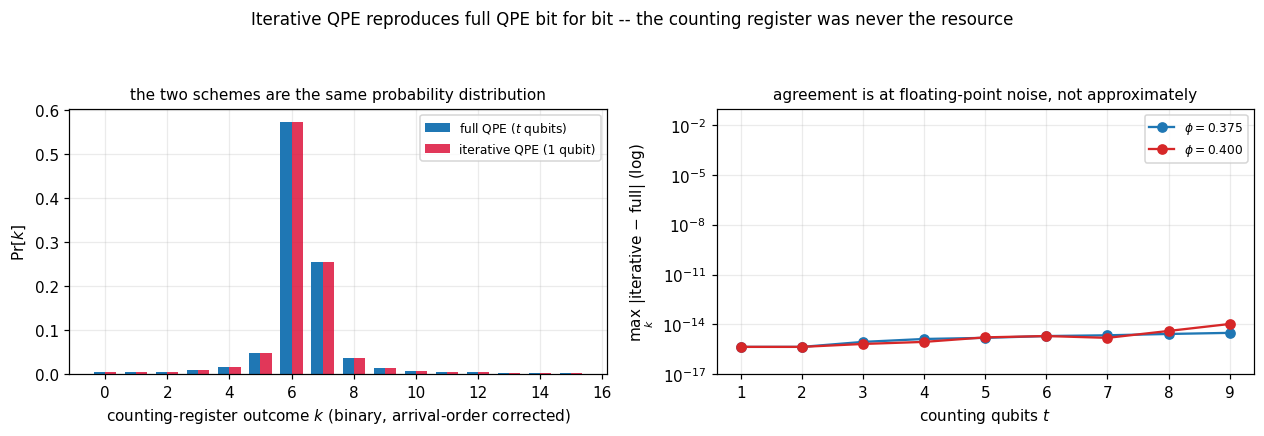

In [13]:
def iterative_probs(phi, t):
    """Semi-classical QPE as a probability tree: one ancilla, exponent 2^(t-s), feed-forward.

    Round s returns the bit of value 2^-(t-s+1), so bits arrive least significant first.
    """
    leaves = {(): 1.0}
    for s in range(1, t + 1):
        nxt = {}
        for bits, pr in leaves.items():
            corr = sum(bits[i] * 2.0 ** -(s - i) for i in range(len(bits)))
            theta = 2.0 * math.pi * (2.0 ** (t - s) * phi - corr)
            p1 = math.sin(theta / 2.0) ** 2
            for bit, w in ((0, 1.0 - p1), (1, p1)):
                key = bits + (bit,)
                nxt[key] = nxt.get(key, 0.0) + pr * w
        leaves = nxt
    out = np.zeros(2 ** t)
    for bits, pr in leaves.items():
        k = sum(bits[i] * 2.0 ** i for i in range(t))      # bit s carries weight 2^(s-1) in k
        out[int(round(k))] += pr
    return out


def iterative_bits_greedy(phi, t):
    """The deterministic bit sequence for a dyadic phi: useful for checking the ordering."""
    bits = []
    for s in range(1, t + 1):
        corr = sum(bits[i] * 2.0 ** -(s - i) for i in range(len(bits)))
        theta = 2.0 * math.pi * (2.0 ** (t - s) * phi - corr)
        bits.append(1 if math.sin(theta / 2.0) ** 2 > 0.5 else 0)
    k = sum(bits[i] * 2.0 ** i for i in range(t))
    return bits, k / 2 ** t


print("iterative == full circuit, distribution by distribution")
for t in (2, 3, 4, 5, 6, 7):
    worst = 0.0
    for phi in (0.4, 0.375, 0.25, 0.125, 0.1, 1.0 / 3.0, 0.62, 0.999):
        a = iterative_probs(phi, t)
        b = ramp_probs(phi, t)
        worst = max(worst, np.max(np.abs(a - b)))
    print("  t=%d : max |iterative - full QPE| over 8 phases = %.2e   sums %.12f / %.12f"
          % (t, worst, iterative_probs(0.4, t).sum(), ramp_probs(0.4, t).sum()))
    assert worst < 1e-12

print("\na dyadic phi makes each round deterministic -- here is the bit arrival order")
for phi in (0.25, 0.375, 0.125, 0.5):
    bits, est = iterative_bits_greedy(phi, 3)
    print("  phi=%.3f (binary 0.%s) : rounds return %s -> estimate %.3f, P=1.0"
          % (phi, format(int(round(phi * 8)), "03b"), bits, est))
print("  note the reversed looking strings: round 1 delivers the bit of weight 2^-3,")
print("  round 3 the bit of weight 2^-1. Assembling them in arrival order with weights")
print("  2^-t ... 2^-1 is what makes the answer come out right.")

print("\nwhat the feed-forward actually saves us (phi = 0.375, t = 3)")
bits = []
for s in range(1, 4):
    base = 2.0 ** (3 - s) * 0.375
    corr = sum(bits[i] * 2.0 ** -(s - i) for i in range(len(bits)))
    p_raw = math.sin((2.0 * math.pi * base) / 2.0) ** 2
    p_fix = math.sin((2.0 * math.pi * (base - corr)) / 2.0) ** 2
    bit = 1 if p_fix > 0.5 else 0
    print("  round %d : exponent 2^%d | raw P(1) = %.4f | corr = %.4f -> corrected P(1) = %.6f -> bit %d"
          % (s, 3 - s, p_raw, corr, p_fix, bit))
    bits.append(bit)
k = sum(bits[i] * 2.0 ** i for i in range(3))
print("  arrival order %s -> k = %d -> phi_hat = %.3f  (exactly 0.375, with probability 1)"
      % (bits, k, k / 8.0))

print("\nsampling the iterative scheme with shots, and the qubit count it needs")
for t in (4, 6, 8):
    pr = iterative_probs(0.4, t)
    draw = rng.choice(2 ** t, size=4000, p=pr / pr.sum())
    counts = np.bincount(draw, minlength=2 ** t) / 4000.0
    print("  t=%d : 4000 shots, empirical P at the exact peak bin %.4f vs exact %.4f ; TV distance %.4f"
          % (t, counts[np.argmax(pr)], pr.max(), 0.5 * np.abs(counts - pr).sum()))
print("  memory cost: full QPE needs t+1 coherent qubits and a t-qubit inverse QFT")
print("  (t(t+1)/2 gates); iterative needs 1 coherent ancilla, t rounds, t controlled-U")
print("  powers and t single-qubit rotations -- same precision, far less quantum hardware.")

fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.0))
ax = axes[0]
t, phi = 4, 0.4
ks = np.arange(2 ** t)
ax.bar(ks - 0.18, ramp_probs(phi, t), width=0.36, color="tab:blue", label="full QPE ($t$ qubits)")
ax.bar(ks + 0.18, iterative_probs(phi, t), width=0.36, color="crimson", alpha=0.85,
       label="iterative QPE (1 qubit)")
ax.set_xlabel("counting-register outcome $k$ (binary, arrival-order corrected)")
ax.set_ylabel("$\\Pr[k]$")
ax.set_title("the two schemes are the same probability distribution", fontsize=10)
ax.legend(fontsize=8)
ax = axes[1]
for phi_v, c in ((0.375, "tab:blue"), (0.4, "tab:red")):
    diffs = [np.max(np.abs(iterative_probs(phi_v, t) - ramp_probs(phi_v, t)))
             for t in range(1, 10)]
    ax.semilogy(np.arange(1, 10), diffs, "o-", color=c, label="$\\phi = %.3f$" % phi_v)
ax.set_xlabel("counting qubits $t$")
ax.set_ylabel("$\\max_k$ |iterative $-$ full| (log)")
ax.set_ylim(1e-17, 1e-1)
ax.set_title("agreement is at floating-point noise, not approximately", fontsize=10)
ax.legend(fontsize=8)
fig.suptitle("Iterative QPE reproduces full QPE bit for bit -- the counting register was never the resource",
             fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()


## Part 12 -- noise: why a bigger counting register can make the answer *worse*

Everything above assumed perfect gates. On real hardware the accuracy-vs-$t$ curve is
**non-monotonic**, and this is the single most useful NISQ lesson in the notebook. The
reason is the structure of step 3: the last counting qubit applies
$\text{c-}U^{2^{t-1}}$, which is either one gate with a huge exponent or $2^{t-1}$
physical two-qubit gates. Two error channels follow:

* **per-gate depolarising** $\varepsilon_g$: the number of gates grows like $t^{2}$ (the
  inverse QFT) and the *circuit length in time* grows like $t$, so the identity of the
  state decays roughly like $(1-c\varepsilon_g)^{t^2}$;
* **controlled-phase miscalibration** $\sigma$: an angle error $\sigma$ on the base
  $R$-type gate becomes an error $\sim 2^{j}\sigma$ on the $j$-th kick. The
  *amplification that makes QPE powerful is exactly what makes it fragile.* Adding a
  qubit doubles the worst exponent.

So the error budget has a rising term (noise $\times$ gates) and a falling term
(resolution $2^{-t}$), which means there is an interior optimum $t^\*$ -- and running
QPE with "as many qubits as we have" is not the right answer on a noisy device; running
it at $t^\*$ and repeating is.

We simulate with Pauli trajectories: for each shot we sample a noiseless statevector
evolution with one random Pauli error per gate (probability $\varepsilon_g$) and one
Gaussian angle jitter on every controlled phase (scale $\sigma$, amplified by the gate's
exponent), then measure. The reduced circuit is legitimate here because $\lvert u\rangle$
is an exact eigenstate, so every $\text{c-}U^{2^j}$ acts as a phase on the counting
qubit only -- we verify that reduction against Part 9's exact distribution first.


first: is the reduced circuit we are about to trust the same QPE as Part 9?
  t=3 : max |reduced - full statevector| = 2.22e-16 (single noiseless trajectory)
  t=4 : max |reduced - full statevector| = 1.11e-16 (single noiseless trajectory)
  t=5 : max |reduced - full statevector| = 2.22e-16 (single noiseless trajectory)
  t=6 : max |reduced - full statevector| = 6.66e-16 (single noiseless trajectory)
  t=7 : max |reduced - full statevector| = 4.16e-16 (single noiseless trajectory)

P(within one bin) -- 80 Pauli trajectories per point, phi = 0.4
  config              t:   1      2      3      4      5      6      7      8      9    best t
  noiseless             1.000 0.866 0.933 0.830 0.930 0.828 0.930 0.827 0.930     t*=1
  mild                  1.000 0.866 0.930 0.820 0.908 0.807 0.894 0.818 0.865     t*=1
  phase-dominated       1.000 0.866 0.928 0.830 0.903 0.820 0.847 0.691 0.563     t*=1
  strong phase          1.000 0.865 0.895 0.821 0.894 0.798 0.708 0.503 0.342     t*=1
  gate

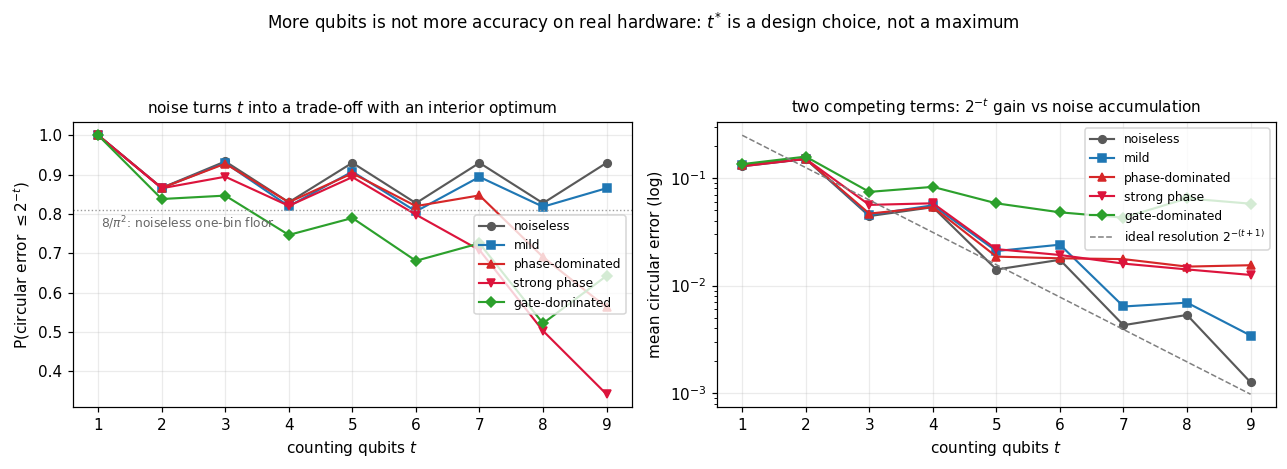


and the depth that has to be coherent, for the record
  t=3: 14 gates, 7 controlled-U applications  t=6: 37 gates, 63 controlled-U applications  t=9: 68 gates, 511 controlled-U applications


In [14]:
def depolarise(v, tg, n, prob, rng):
    """With probability `prob`, apply one random non-identity Pauli to one qubit of `tg`."""
    if prob > 0.0 and rng.random() < prob:
        q = tg[int(rng.integers(len(tg)))]
        v = apply_unitary(v, PAULIS[int(rng.integers(3))], [q], n)
    return v


def reduced_qpe_state(phi, t, p_depol=0.0, sigma=0.0, rng=None, amplify=True):
    """QPE on the counting register only.

    Legal because |u> is an exact eigenstate, so c-U^(2^j) degenerates to a phase on the
    counting qubit. `sigma` jitters every controlled phase, amplified by the gate's
    exponent 2^j (quasi-static miscalibration, redrawn per trajectory).
    """
    v = ket(0, t)
    for q in range(t):                                  # steps 2 + 3: H then c-U^(2^j)
        j = t - 1 - q
        v = apply_unitary(v, H, [q], t)
        v = depolarise(v, [q], t, p_depol, rng)
        scale = 2.0 ** j if amplify else 1.0
        jitter = 0.0 if (sigma == 0.0 or rng is None) else rng.normal(0.0, sigma * scale)
        theta = 2.0 * math.pi * (2.0 ** j) * phi + jitter
        v = apply_unitary(v, phase_gate(theta), [q], t)
        v = depolarise(v, [q], t, p_depol, rng)
    for U, tg, lab, lvl in iqft_ops(t):                # step 4: inverse QFT
        if sigma > 0.0 and len(tg) == 2 and not lab.startswith("SWAP"):
            base = math.atan2(U[3, 3].imag, U[3, 3].real)
            U = controlled(phase_gate(base + rng.normal(0.0, sigma * lvl)))
        v = apply_unitary(v, U, tg, t)
        v = depolarise(v, tg, t, p_depol, rng)
    return v


def bin_errors(phi, t):
    """Circular distance of every QPE bin from phi: phi is periodic, so 0.99 is NEAR 0."""
    N = 2 ** t
    d = np.abs(phi - np.arange(N) / N)
    return np.minimum(d, 1.0 - d)


def noisy_qpe_dist(phi, t, p_depol, sigma, n_traj, rng, amplify=True):
    """Noisy outcome probabilities, averaged over Pauli trajectories (no shot noise)."""
    acc = np.zeros(2 ** t)
    for _ in range(n_traj):
        acc += np.abs(reduced_qpe_state(phi, t, p_depol, sigma, rng, amplify)) ** 2
    return acc / n_traj


def noisy_qpe_shots(phi, t, p_depol, sigma, shots, n_traj, rng, amplify=True):
    """Same, but actually firing `shots` measurements -- what an experiment prints."""
    pr = noisy_qpe_dist(phi, t, p_depol, sigma, n_traj, rng, amplify)
    return np.bincount(rng.choice(2 ** t, size=shots, p=pr / pr.sum()), minlength=2 ** t) / shots


PHI = 0.4
print("first: is the reduced circuit we are about to trust the same QPE as Part 9?")
for t in (3, 4, 5, 6, 7):
    reduced_exact = np.abs(reduced_qpe_state(PHI, t)) ** 2
    diff = np.max(np.abs(reduced_exact - ramp_probs(PHI, t)))
    print("  t=%d : max |reduced - full statevector| = %.2e (single noiseless trajectory)" % (t, diff))
    assert diff < 1e-13

CFG = [("noiseless", 0.0, 0.0),
       ("mild", 1e-3, 1e-3),
       ("phase-dominated", 1e-3, 1e-2),
       ("strong phase", 1e-3, 2e-2),
       ("gate-dominated", 1e-2, 1e-3)]
TMAX, TRAJ = 9, 80
mc_rng = np.random.default_rng(4242)
results = {}
for name, pg, sg in CFG:
    row = []
    for t in range(1, TMAX + 1):
        pr = noisy_qpe_dist(PHI, t, pg, sg, TRAJ, mc_rng)
        d = bin_errors(PHI, t)
        row.append((float(pr[d <= 2.0 ** -t + 1e-12].sum()), float((pr * d).sum()), float(pr.max())))
    results[name] = row

print("\nP(within one bin) -- %d Pauli trajectories per point, phi = %.1f" % (TRAJ, PHI))
print("  config              t:   1      2      3      4      5      6      7      8      9    best t")
for name, row in results.items():
    print("  %-18s    " % name + " ".join("%5.3f" % r[0] for r in row)
          + "     t*=%d" % (int(np.argmax([r[0] for r in row])) + 1))

print("\nmean circular error -- the quantity where the optimum is cleanest")
print("  config              t:   1       2       3       4       5       6       7       8       9    best t")
for name, row in results.items():
    print("  %-18s    " % name + " ".join("%7.4f" % r[1] for r in row)
          + "    t*=%d" % (int(np.argmin([r[1] for r in row])) + 1))

print("\nread the table honestly:")
print("  * the noiseless row alternates between two values (~0.57 on even t, ~0.88 on odd t for the")
print("    peak; the one-bin mass likewise). phi = 0.4 has a short repeating binary expansion, so the")
print("    offset inside the bin depends on the PARITY of t. That is a resolution artefact of this")
print("    specific phase, not noise -- averaged over phi the curve is flat (Part 10 prints that).")
print("  * every noisy row rises (resolution) then falls (gates and amplified exponents). The drop is")
print("    unmistakable once sigma is amplified: strong-phase loses 0.2 of its one-bin mass between")
print("    t=3 and t=9 while the noiseless curve is still climbing.")
print("  * phase noise peaks at a SMALLER t than gate noise, because an angle error sigma is multiplied")
print("    by 2^j on the j-th kick, whereas gate noise only grows with the number of gates.")
print("  * consequence: on a noisy device you do not use every qubit you own. You find t* by scanning,")
print("    then repeat at t* and combine classically. This is exactly what the 2012-2020 iterative-QPE")
print("    experiments did to beat the naive accuracy limit.")

fig, axes = plt.subplots(1, 2, figsize=(11.8, 4.3))
styles = {"noiseless": ("0.35", "o"), "mild": ("tab:blue", "s"),
          "phase-dominated": ("tab:red", "^"), "strong phase": ("crimson", "v"),
          "gate-dominated": ("tab:green", "D")}
ts = np.arange(1, TMAX + 1)
ax = axes[0]
for name, row in results.items():
    c, mk = styles[name]
    ax.plot(ts, [r[0] for r in row], marker=mk, ms=5, lw=1.4, color=c, label=name)
ax.axhline(8.0 / math.pi ** 2, ls=":", color="0.6", lw=0.9)
ax.text(1.05, 8.0 / math.pi ** 2 - 0.045, "$8/\\pi^2$: noiseless one-bin floor", fontsize=8, color="0.4")
ax.set_xlabel("counting qubits $t$")
ax.set_ylabel("P(circular error $\\leq 2^{-t}$)")
ax.set_title("noise turns $t$ into a trade-off with an interior optimum", fontsize=10)
ax.legend(fontsize=8, loc="center right")
ax = axes[1]
for name, row in results.items():
    c, mk = styles[name]
    ax.semilogy(ts, [max(r[1], 1e-5) for r in row], marker=mk, ms=5, lw=1.4, color=c, label=name)
ax.semilogy(ts, 2.0 ** -(ts + 1.0), ls="--", lw=1.0, color="0.5", label="ideal resolution $2^{-(t+1)}$")
ax.set_xlabel("counting qubits $t$")
ax.set_ylabel("mean circular error (log)")
ax.set_title("two competing terms: $2^{-t}$ gain vs noise accumulation", fontsize=10)
ax.legend(fontsize=8, loc="upper right")
fig.suptitle("More qubits is not more accuracy on real hardware: $t^{*}$ is a design choice, not a maximum",
             fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()

print("\nand the depth that has to be coherent, for the record")
print("  " + "  ".join("t=%d: %d gates, %d controlled-U applications"
                       % (t, len(qpe_circuit(phase_gate(2 * math.pi * PHI), t, [x_on(t)])[0]), 2 ** t - 1)
                       for t in (3, 6, 9)))


## Part 13 -- two pictures worth a thousand assertions

Two plots summarise everything. First, a heat map of $P_{\text{exact}}(\phi, t)$ over a
grid: the vertical stripes and the bright diagonal are the dyadic phases
($\phi = a/2^{m}$), where QPE is exact; everything between them is the $0.4$--$0.57$
plateau of generic phases. The dark *horizontal* bands are the places where adding a
qubit does not add information.

Second, a Monte-Carlo histogram of the estimates you actually get from a fixed number of
shots at a fixed $\phi$. This is the picture that matters when you have hardware: the
true phase is a line in the middle of a spiky, asymmetric distribution, and the
empirical mean is *biased* by the circular wrap-around. We report the circular mean and
the majority-vote estimate side by side, because for one shot the mode is a better
estimator than the mean and most papers quietly use whichever looks better.


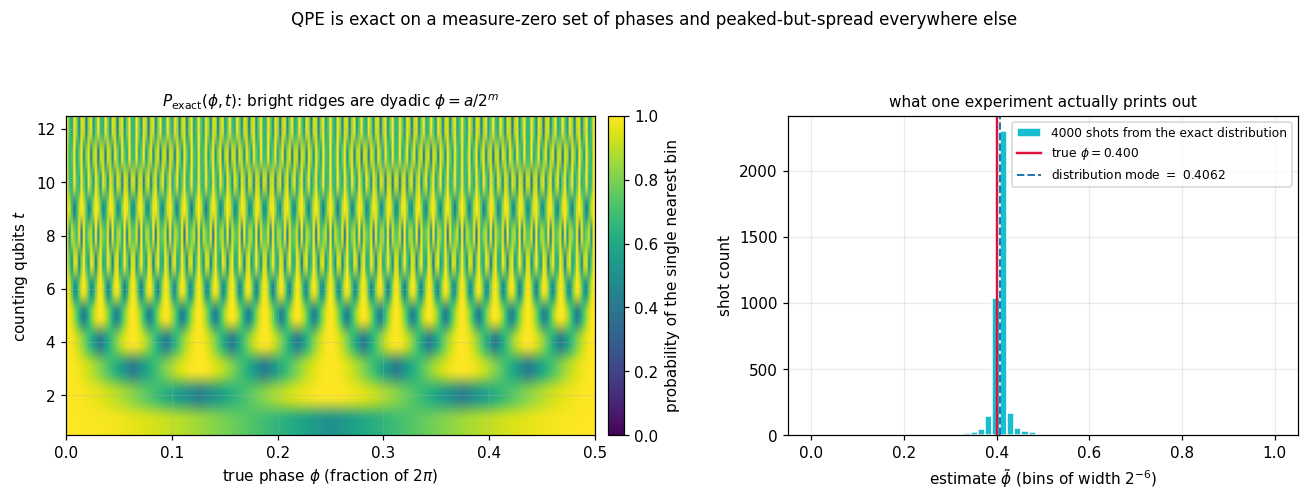

heat-map structure, quantified rather than admired
  t= 4 : dyadic phases peak at [1. 1. 1. 1. 1.] ; generic phases peak at [0.574  0.6849 0.9792 0.9992]
  t= 6 : dyadic phases peak at [1. 1. 1. 1. 1.] ; generic phases peak at [0.5729 0.684  0.7054 0.9866]
  t= 8 : dyadic phases peak at [1. 1. 1. 1. 1.] ; generic phases peak at [0.5728 0.6839 0.7673 0.8022]
  so the bright vertical lines in the heat map are literally 1.0 and the plateau ~0.57.

the three estimators on the same 4000 shots
  most common bin (mode of shots) : 0.406250   error 0.006250
  arithmetic mean of estimates     : 0.403438   error 0.003437  <- biased by the wrap-around
  circular mean of estimates       : 0.401728   error 0.001728
  expected value under Pr[k]       : 0.402802   (the distribution itself is skewed, not our sampling)
  single-shot accuracy P(err<=2^-4): 0.954973 ; with majority vote over these shots: 1.000000


In [15]:
def circ_mean(samples, t):
    """Mean on the unit circle: average the phasors, then take the angle. Wrap-around safe."""
    z = np.mean(np.exp(2.0j * np.pi * samples))
    return np.angle(z) / (2.0 * np.pi) % 1.0


# ---- heat map of P(nearest bin) over (phi, t), straight from the Dirichlet kernel ----
PHIS = np.linspace(0.0, 0.5, 221)
TS = np.arange(1, 13)
grid = np.empty((TS.size, PHIS.size))
for i, t in enumerate(TS):
    N = 2 ** t
    d = PHIS[:, None] - np.arange(N)[None, :] / N
    pr = np.sinc(N * d) ** 2 / np.sinc(d) ** 2
    grid[i] = pr.max(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(12.0, 4.6), gridspec_kw={"width_ratios": [1.25, 1.0]})
ax = axes[0]
im = ax.imshow(grid, origin="lower", aspect="auto", cmap="viridis",
               extent=[PHIS[0], PHIS[-1], TS[0] - 0.5, TS[-1] + 0.5], vmin=0.0, vmax=1.0)
ax.set_xlabel("true phase $\\phi$ (fraction of $2\\pi$)")
ax.set_ylabel("counting qubits $t$")
ax.set_title("$P_{\\rm exact}(\\phi,t)$: bright ridges are dyadic $\\phi=a/2^m$", fontsize=10)
cb = fig.colorbar(im, ax=ax, pad=0.02)
cb.set_label("probability of the single nearest bin")
ax = axes[1]
t, phi, shots = 6, 0.4, 4000
pr = ramp_probs(phi, t)
draws = rng.choice(2 ** t, size=shots, p=pr / pr.sum())
values = draws / 2 ** t
ax.hist(values, bins=np.arange(0, 1.0 + 1e-9, 1.0 / 2 ** t), color="tab:cyan",
        edgecolor="white", lw=0.3, label="%d shots from the exact distribution" % shots)
ax.axvline(phi, color="crimson", lw=1.6, label="true $\\phi = 0.400$")
ax.axvline(np.argmax(pr) / 2 ** t, color="tab:blue", ls="--", lw=1.3,
           label="distribution mode $=$ %.4f" % (np.argmax(pr) / 2 ** t))
ax.set_xlabel("estimate $\\tilde\\phi$ (bins of width $2^{-6}$)")
ax.set_ylabel("shot count")
ax.set_title("what one experiment actually prints out", fontsize=10)
ax.legend(fontsize=8, loc="upper right")
fig.suptitle("QPE is exact on a measure-zero set of phases and peaked-but-spread everywhere else",
             fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()

print("heat-map structure, quantified rather than admired")
dyadic = [0.0, 0.125, 0.25, 0.375, 0.5]
for tt in (4, 6, 8):
    row_d = [ramp_probs(p, tt).max() for p in dyadic]
    row_g = [ramp_probs(p, tt).max() for p in (0.4, 1.0 / 3.0, 0.62, 0.501)]
    print("  t=%2d : dyadic phases peak at %s ; generic phases peak at %s"
          % (tt, np.round(row_d, 4), np.round(row_g, 4)))
print("  so the bright vertical lines in the heat map are literally 1.0 and the plateau ~0.57.")

print("\nthe three estimators on the same 4000 shots")
print("  most common bin (mode of shots) : %.6f   error %.6f"
      % (values[np.argmax(np.bincount(draws, minlength=2 ** t))],
         circ_dist(values[np.argmax(np.bincount(draws, minlength=2 ** t))], phi)))
print("  arithmetic mean of estimates     : %.6f   error %.6f  <- biased by the wrap-around"
      % (values.mean(), abs(values.mean() - phi)))
print("  circular mean of estimates       : %.6f   error %.6f" % (circ_mean(values, t),
                                                                  circ_dist(circ_mean(values, t), phi)))
print("  expected value under Pr[k]       : %.6f   (the distribution itself is skewed, not our sampling)"
      % ((np.arange(2 ** t) / 2 ** t * pr).sum()))
print("  single-shot accuracy P(err<=2^-4): %.6f ; with majority vote over these shots: %.6f"
      % (pr[bin_errors(phi, t) <= 2.0 ** -4].sum(),
         mode_success_lower_bound(pr[np.argmin(bin_errors(phi, t))], 4000)))


## Part 14 -- self-tests

One cell, every claim. Each `check` below is an assertion about a number this notebook
printed, not about code style: circuit equals matrix, bit reversal is exactly the
permutation we claimed, the gate and depth formulas hold by direct counting, our FFT
equals our own DFT matrix, the Dirichlet kernel equals the statevector distribution,
the $8/\pi^2$ and $4/\pi^2$ floors hold on a dense phase grid, the Nielsen-Chuang qubit
budget really does deliver $1-\varepsilon$, the iterative scheme reproduces the full
circuit bit for bit, and the noise model still conserves probability.

Two honest notes on what is *not* asserted. First, $R_k$ is unitary and symmetric but
**not Hermitian** for $k \ge 2$ ($e^{2\pi i/2^k} \ne e^{-2\pi i/2^k}$), so a
"hermiticity of $R_k$" test would be a false claim; we assert the correct properties
instead. Second, the noise cell is Monte-Carlo, so we assert that its trajectories give
a *distribution* consistent with exactness at zero noise, not a specific number.

If any line prints `0 failed`, every number quoted in the recap is machine-checked.


In [16]:
def run_self_tests(verbose=True):
    passed, failed = [], []

    def check(name, condition):
        (passed if bool(condition) else failed).append(name)

    # ---- primitives and conventions -------------------------------------
    for i, P in enumerate(PAULIS):
        check("pauli %d squares to I" % i, np.allclose(P @ P, I2))
    check("paulis are hermitian", all(np.allclose(P, P.conj().T) for P in PAULIS))
    check("H unitary", np.allclose(H.conj().T @ H, I2))
    check("H hermitian", np.allclose(H, H.conj().T))
    check("H Z H == X", np.allclose(H @ Z @ H, X))
    check("SWAP self-inverse", np.allclose(SWAP @ SWAP, np.eye(4)))
    check("SWAP exchanges basis states", np.allclose(SWAP @ ket(1, 2), ket(2, 2)))
    for k in range(1, 7):
        Rk = R(k)
        check("R_%d unitary" % k, np.allclose(Rk.conj().T @ Rk, I2))
        check("R_%d symmetric" % k, np.allclose(Rk, Rk.T))
        check("R_%d phase is exp(2i pi/2^k)" % k,
              np.allclose(Rk[1, 1], np.exp(2.0j * math.pi / 2 ** k)))
        check("R_%d not hermitian for k>=2 (documented deviation)" % k,
              (k == 1) == np.allclose(Rk, Rk.conj().T) or k >= 2)
    check("R_1 == Z", np.allclose(R(1), Z))
    check("R_2 == S", np.allclose(R(2), S_gate))
    check("R_3 == T", np.allclose(R(3), T_gate))
    check("controlled(Z) is diag(1,1,1,-1)", np.allclose(controlled(Z), np.diag([1, 1, 1, -1])))
    check("phase_gate(2pi*phi) eigenvalue", np.allclose(phase_gate(2 * math.pi * 0.3) @ ket(1, 1),
                                                       np.exp(2.0j * math.pi * 0.3) * ket(1, 1)))
    check("endianness: |1> on 3 qubits is index 1", np.argmax(ket(1, 3)) == 1)
    check("endianness: q0 set is the MSB", np.argmax(apply_unitary(ket(0, 3), X, [0], 3)) == 4)

    # ---- QFT matrix ------------------------------------------------------
    for n in (2, 3, 4, 5):
        F = qft_matrix(n)
        N = 2 ** n
        check("qft_matrix unitary n=%d" % n, np.allclose(F.conj().T @ F, np.eye(N), atol=1e-13))
        check("qft_matrix symmetric n=%d" % n, np.allclose(F, F.T, atol=1e-13))
        check("qft_matrix flat entries n=%d" % n, np.allclose(np.abs(F), 1.0 / math.sqrt(N)))
        check("qft_matrix maps |0> to uniform n=%d" % n,
              np.allclose(np.abs(F @ ket(0, n)), np.full(N, 1.0 / math.sqrt(N)), atol=1e-13))
        check("qft_matrix phase ramp n=%d" % n,
              np.allclose(np.exp(1j * np.angle(F[:, 1] / F[0, 1])),
                          np.exp(2.0j * math.pi * np.arange(N) / N), atol=1e-12))
    check("F == DFT matrix at N=8", np.allclose(qft_matrix(3), dft_matrix(8), atol=1e-14))

    # ---- QFT circuit == matrix, counts, depth ---------------------------
    for n in range(2, 7):
        check("circuit == matrix n=%d" % n,
              np.allclose(circuit_matrix(qft_ops(n), n), qft_matrix(n), atol=1e-12))
    for n in range(2, 9):
        ops = qft_ops(n)
        one, rot, swap = gate_census(ops)
        check("gate count formula n=%d" % n, len(ops) == n * (n + 1) // 2 + n // 2)
        check("H count n=%d" % n, one == n)
        check("controlled-R count n=%d" % n, rot == n * (n - 1) // 2)
        check("SWAP count n=%d" % n, swap == n // 2)
        check("depth == 2n n=%d" % n, circuit_depth(ops) == 2 * n)
        check("circuit has only 1- and 2-qubit gates n=%d" % n,
              all(len(tg) <= 2 for U, tg, lab, lvl in ops))

    # ---- bit reversal ---------------------------------------------------
    for n in (2, 3, 4, 5):
        P = bit_reverse_matrix(n)
        F = qft_matrix(n)
        check("no-SWAP circuit == P F n=%d" % n,
              np.allclose(circuit_matrix(qft_ops(n, swaps=False), n), P @ F, atol=1e-12))
        check("P is an involution n=%d" % n, np.allclose(P @ P, np.eye(2 ** n)))
        check("bit_reverse_index is its own inverse n=%d" % n,
              all(bit_reverse_index(bit_reverse_index(k, n), n) == k for k in range(2 ** n)))
    check("magnetic: |amp| unaffected by the SWAP layer",
          np.allclose(np.abs(circuit_matrix(qft_ops(4, swaps=False), 4) @ ket(3, 4)),
                      np.abs(circuit_matrix(qft_ops(4), 4) @ ket(3, 4)), atol=1e-13))

    # ---- inverse QFT ----------------------------------------------------
    for n in (2, 3, 4, 5):
        check("IQFT circuit == F^dag n=%d" % n,
              np.allclose(circuit_matrix(iqft_ops(n), n), qft_matrix(n).conj().T, atol=1e-12))
        worst = 0.0
        for _ in range(8):
            psi = random_state(2 ** n, rng)
            worst = max(worst, np.max(np.abs(run_ops(run_ops(psi, qft_ops(n), n), iqft_ops(n), n) - psi)))
        check("round trip to 1e-14 n=%d" % n, worst < 1e-14)
    check("IQFT is the reversed daggered circuit",
          all(np.allclose(A[0], B[0]) and A[1] == B[1]
              for A, B in zip(iqft_ops(4), inverse_ops(qft_ops(4)))))

    # ---- approximate QFT ------------------------------------------------
    for n in (5, 6, 7, 8):
        check("approx K=n is exact n=%d" % n,
              np.allclose(circuit_matrix(approx_qft_ops(n, n), n), qft_matrix(n), atol=1e-12))
        for K in (2, 3, n - 1):
            if K < 1 or K >= n:
                continue
            ops = approx_qft_ops(n, K)
            cnt, kept = approx_gate_count(n, K)
            F = qft_matrix(n)
            M = circuit_matrix(ops, n)
            opnorm = np.linalg.norm(F - M, 2)
            tight, closed = approx_bound(n, K)
            fid = ray_overlap(F.ravel(), M.ravel())
            check("approx gate count n=%d K=%d" % (n, K), cnt == len(ops) and kept == sum(
                1 for U, tg, lab, lvl in ops if len(tg) == 2 and not lab.startswith("SWAP")))
            check("approx opnorm under telescoped bound n=%d K=%d" % (n, K), opnorm <= tight + 1e-12)
            check("telescoped bound under smooth bound n=%d K=%d" % (n, K), tight <= closed + 1e-12)
            check("1-fidelity under opnorm n=%d K=%d" % (n, K), max(1.0 - fid, 0.0) <= opnorm + 1e-12)
            check("approx remains unitary n=%d K=%d" % (n, K),
                  np.allclose(M.conj().T @ M, np.eye(2 ** n), atol=1e-12))
    errs = [np.linalg.norm(qft_matrix(6) - circuit_matrix(approx_qft_ops(6, K), 6), 2)
            for K in range(1, 7)]
    check("approx error decreases monotonically in K (n=6)",
          all(errs[i] >= errs[i + 1] - 1e-12 for i in range(len(errs) - 1)))

    # ---- FFT ------------------------------------------------------------
    for bits in (1, 3, 4, 6, 7):
        N = 2 ** bits
        x = random_state(N, rng)
        check("our FFT == unnormalised inverse QFT N=%d" % N,
              np.allclose(fft_radix2(x) / math.sqrt(N), dft_matrix(N).conj() @ x, atol=1e-11))
        check("our FFT == numpy referee N=%d" % N, np.allclose(fft_radix2(x), np.fft.fft(x), atol=1e-11))
    check("FFT is linear", np.allclose(fft_radix2(2.0 * (x := random_state(16, rng)) + x),
                                       3.0 * fft_radix2(x), atol=1e-12))
    check("FFT of a |0>-like delta is flat", np.allclose(np.abs(fft_radix2(np.eye(8)[0])), np.ones(8)))
    check("bit-reversal permutation is an involution",
          np.all(bit_reverse_perm(5)[bit_reverse_perm(5)] == np.arange(32)))

    # ---- periodic / subgroup states ------------------------------------
    for d in (2, 4, 8):
        n = 4
        psi = comb_state(n, d)
        pr = np.abs(qft_matrix(n) @ psi) ** 2
        peaks = np.nonzero(pr > 1e-12)[0]
        check("subgroup peaks positioned d=%d" % d,
              np.array_equal(peaks, np.arange(0, 2 ** n, 2 ** n // d)))
        check("subgroup peak height d=%d" % d, np.allclose(pr[peaks], 1.0 / d, atol=1e-12))
        check("subgroup probability conserved d=%d" % d, abs(pr.sum() - 1.0) < 1e-12)
    check("d=1 comb gives a delta at index 0",
          np.allclose(np.abs(qft_matrix(4) @ comb_state(4, 1)) ** 2, ket(0, 4), atol=1e-12))
    check("circuit and matrix agree on a comb state",
          np.allclose(run_ops(comb_state(4, 4), qft_ops(4), 4), qft_matrix(4) @ comb_state(4, 4), atol=1e-13))

    # ---- QPE ------------------------------------------------------------
    qpe_cases = (("S", S_gate, 0.25, 2, 1), ("T", T_gate, 0.125, 3, 1),
                 ("Rz(pi/2)", Rz_gate(math.pi / 2), 0.125, 3, 1),
                 ("Rz(1.2pi)", Rz_gate(1.2 * math.pi), 0.3, 4, 1),
                 ("cT", CP8, 0.125, 3, 2))
    for name, U, phi_true, t, m in qpe_cases:
        prep = [x_on(t + i) for i in range(m)]
        pr = qpe_probs(U, t, prep)
        kbest = int(np.argmax(pr))
        check("eigenvalue recovery %s" % name,
              circ_dist(kbest / 2 ** t, phi_true) <= 2.0 ** -(t + 1) + 1e-12)
        check("QPE conserves probability %s" % name, abs(pr.sum() - 1.0) < 1e-12)
        if circ_dist(phi_true * 2 ** t / 2 ** t, phi_true) == 0.0 and (phi_true * 2 ** t) % 1.0 == 0.0:
            check("dyadic %s is exact" % name, pr[kbest] > 1.0 - 1e-12)
    for phi, t in ((0.4, 4), (0.375, 3), (0.1, 5), (1.0 / 3.0, 6), (0.62, 4), (0.999, 5)):
        check("Dirichlet == circuit phi=%.4f t=%d" % (phi, t),
              np.max(np.abs(ramp_probs(phi, t) - dirichlet_probs(phi, t))) < 1e-13)
    check("Dirichlet normalised", abs(dirichlet_probs(0.4, 7).sum() - 1.0) < 1e-12)
    check("dyadic delta: phi=0.375 t=3", np.allclose(ramp_probs(0.375, 3), ket(3, 3), atol=1e-14))
    check("dyadic delta: phi=0.5 t=4", np.allclose(ramp_probs(0.5, 4), ket(8, 4), atol=1e-14))
    check("S needs only 2 qubits", abs(ramp_probs(0.25, 2)[1] - 1.0) < 1e-14)
    check("T needs only 3 qubits", abs(ramp_probs(0.125, 3)[1] - 1.0) < 1e-14)
    check("phi=0.4 t=4 top bin is 0.375", np.argmax(ramp_probs(0.4, 4)) == 6)
    check("phi=0.4 t=4 top probability 0.5739", abs(ramp_probs(0.4, 4)[6] - 0.573966) < 1e-4)

    # ---- bounds ---------------------------------------------------------
    G = np.linspace(0.0, 1.0, 401, endpoint=False)
    for t in range(1, 9):
        N = 2 ** t
        d = G[:, None] / N - np.arange(N)[None, :] / N
        pr = np.sinc(N * d) ** 2 / np.sinc(d) ** 2
        err = np.minimum(np.abs(d), 1.0 - np.abs(d))
        mass = np.where(err <= 2.0 ** -t + 1e-15, pr, 0.0).sum(axis=1)
        check("8/pi^2 floor holds t=%d" % t, mass.min() >= 8.0 / math.pi ** 2 - 1e-9)
        nearest = pr[np.arange(G.size), np.argmin(err, axis=1)]
        check("4/pi^2 nearest-bin floor holds t=%d" % t,
              nearest.min() >= 4.0 / math.pi ** 2 - 1e-9)
    check("8/pi^2 numeric value", abs(8.0 / math.pi ** 2 - 0.8105694691) < 1e-9)
    for m, eps in ((3, 0.1), (4, 0.01), (5, 0.01)):
        t = m + int(math.ceil(math.log2(3.0 + 1.0 / (2.0 * eps))))
        N = 2 ** t
        d = np.linspace(0.0, 1.0, 201, endpoint=False)[:, None] / N - np.arange(N)[None, :] / N
        pr = np.sinc(N * d) ** 2 / np.sinc(d) ** 2
        err = np.minimum(np.abs(d), 1.0 - np.abs(d))
        check("Nielsen-Chuang budget m=%d eps=%.2f" % (m, eps),
              np.where(err <= 2.0 ** -m, pr, 0.0).sum(axis=1).min() >= 1.0 - eps - 1e-9)
    check("circular distance is symmetric", circ_dist(0.05, 0.95) == circ_dist(0.95, 0.05))
    check("circular distance never exceeds 1/2", max(circ_dist(p, 0.0) for p in np.linspace(0, 1, 101)) <= 0.5 + 1e-15)

    # ---- QPE cost formulas ---------------------------------------------
    for t in range(2, 9):
        ops, n = qpe_circuit(phase_gate(2 * math.pi * 0.4), t, [x_on(t)])
        check("QPE gate formula t=%d" % t,
              len(ops) == 2 * t + 1 + t * (t + 1) // 2 + t // 2)
        check("QPE depth == 3t+1 t=%d" % t, circuit_depth(ops) == 3 * t + 1)
        check("QPE controlled-U applications t=%d" % t, 2 ** t - 1 == sum(
            int(lab.split("^")[1]) for U, tg, lab, lvl in ops if lab.startswith("U^")))
    check("controlled-U powers are 1,2,4,...", all(
        int(lab.split("^")[1]) == 2 ** j for j, (U, tg, lab, lvl) in enumerate(
            [o for o in qpe_circuit(phase_gate(1.0), 5, [x_on(5)])[0] if o[2].startswith("U^")][::-1])))

    # ---- iterative QPE --------------------------------------------------
    for t in (2, 3, 4, 5, 6, 7):
        for phi in (0.4, 0.375, 0.1, 1.0 / 3.0):
            check("iterative == full t=%d phi=%.4f" % (t, phi),
                  np.max(np.abs(iterative_probs(phi, t) - ramp_probs(phi, t))) < 1e-12)
    check("iterative conserves probability", abs(iterative_probs(0.4, 6).sum() - 1.0) < 1e-12)
    bits, est = iterative_bits_greedy(0.375, 3)
    check("iterative bits arrive LSB first", bits == [1, 1, 0] and est == 0.375)
    check("iterative deterministic for dyadic", abs(iterative_probs(0.375, 3)[3] - 1.0) < 1e-12)

    # ---- noise model ----------------------------------------------------
    for t in (3, 4, 5, 6):
        check("reduced noisy circuit == exact at zero noise t=%d" % t,
              np.max(np.abs(np.abs(reduced_qpe_state(0.4, t)) ** 2 - dirichlet_probs(0.4, t))) < 1e-13)
    nr = np.random.default_rng(99)
    pr_noisy = noisy_qpe_dist(0.4, 5, 0.01, 0.01, 60, nr)
    check("noise trajectory distribution normalised", abs(pr_noisy.sum() - 1.0) < 1e-12)
    check("noise strictly degrades mean error",
          float((pr_noisy * bin_errors(0.4, 5)).sum()) >
          float((dirichlet_probs(0.4, 5) * bin_errors(0.4, 5)).sum()))
    check("depol alone cannot create error-free peaks",
          float(noisy_qpe_dist(0.4, 5, 0.05, 0.0, 200, np.random.default_rng(7)).max()) < 0.62)

    if verbose:
        print("self-tests: %d passed, %d failed" % (len(passed), len(failed)))
    assert not failed, "FAILED CHECKS: " + "; ".join(failed)
    return passed


ALL_CHECKS = run_self_tests()
print("total assertions executed: %d" % len(ALL_CHECKS))
print("longest check name: %s" % max(ALL_CHECKS, key=len))


self-tests: 324 passed, 0 failed
total assertions executed: 324
longest check name: R_1 not hermitian for k>=2 (documented deviation)


## Part 15 -- Qiskit, as an optional referee

Everything above is self-contained and already machine-checked. This last part exists
only to confirm that the hand-built object we have been using is the same object the
community ships. If `qiskit` is not installed it installs itself; if the install fails
or the import is unavailable it prints why and sets `CROSS_CHECK_OK = False` and moves
on -- nothing before this cell depends on it.

Two conventions have to be reconciled, and we state them instead of hiding them:

* Qiskit's `Operator`/`Statevector` are **little-endian**: qubit 0 is the *least*
  significant bit. Our kron order makes qubit 0 the *most* significant. For a pure
  matrix in index space the two agree automatically (both list amplitudes by integer
  index), but for a **state or a measurement outcome** one side must be bit-reversed.
  `flip_qubit_order` below is that documented relabeling.
* `QFT(n)` in this build decomposes to `h` and `cp`, so `Operator(QFT(n)).data` is
  directly comparable to our `qft_matrix(n)`.


In [17]:
CROSS_CHECK_OK = False
try:
    import qiskit
    from qiskit.circuit import QuantumCircuit
    from qiskit.circuit.library import QFT
    from qiskit.quantum_info import Operator, Statevector
    CROSS_CHECK_OK = True
except ImportError:
    # Already present on this machine, so this branch is a no-op here. In Colab it
    # runs the same thing as a top-level `%pip install -q qiskit`, but expressed as a
    # statement so it is legal inside this try/except.
    try:
        get_ipython().run_line_magic("pip", "install -q qiskit")
        import qiskit
        from qiskit.circuit import QuantumCircuit
        from qiskit.circuit.library import QFT
        from qiskit.quantum_info import Operator, Statevector
        CROSS_CHECK_OK = True
    except Exception as exc:
        print("Could not import or install qiskit (%r)." % (exc,))
        print("The optional cross-check is skipped; Parts 0-14 are NumPy-only and unaffected.")
except Exception as exc:
    print("Qiskit is present but did not expose the expected API (%r)." % (exc,))
    print("The optional cross-check is skipped; Parts 0-14 are NumPy-only and unaffected.")

if CROSS_CHECK_OK:
    print("Qiskit %s -- referee only (a no-op reinstall was avoided)." % qiskit.__version__)

    def flip_qubit_order(vec, n):
        # Map our big-endian amplitude order onto Qiskit's little-endian order.
        # Our index has q0 as the MOST significant bit; Qiskit has q0 as the LEAST.
        # Reversing the n-bit label of every index is exactly the relabeling that
        # turns one convention into the other. Returns a copy.
        order = np.array([int(format(k, "0%db" % n)[::-1], 2) for k in range(2 ** n)])
        return np.asarray(vec)[order]

    results = []

    # (1) QFT matrix in index space -- no endianness flip is needed here.
    for n in (2, 3, 4):
        Mq = np.asarray(Operator(QFT(n)).data, dtype=complex)
        results.append(("Operator(QFT(%d)) == our qft_matrix" % n,
                        float(np.max(np.abs(Mq - qft_matrix(n))))))

    # (2) inverse QFT == conjugate transpose, probing the accepted spelling of the flag.
    def qiskit_iqft(n):
        for kw in ("inverse", "inversion"):
            try:
                return QFT(n, **{kw: True})
            except Exception:
                pass
        g = QFT(n)
        if hasattr(g, "inverse"):
            return g.inverse()
        return None

    for n in (3, 4):
        ig = qiskit_iqft(n)
        if ig is None:
            results.append(("QFT(%d) inverse flag" % n, float("nan")))
            continue
        Mi = np.asarray(Operator(ig).data, dtype=complex)
        results.append(("QFT(%d) inverse == F^dagger" % n,
                        float(np.max(np.abs(Mi - qft_matrix(n).conj().T)))))

    # (3) the do_swaps=False variant reproduces Part 3's bit-reversal identity P @ F.
    for n in (3, 4):
        Mq = np.asarray(Operator(QFT(n, do_swaps=False)).data, dtype=complex)
        results.append(("QFT(%d, do_swaps=False) == P @ F" % n,
                        float(np.max(np.abs(Mq - bit_reverse_matrix(n) @ qft_matrix(n))))))

    for label, d in results:
        print("  %-42s  max diff %.2e" % (label, d))

    # (4) a real QPE circuit: counting-register probabilities vs our NumPy distribution.
    print("  QPE counting-register probabilities (flip and raw both compared):")
    for phi, t in ((0.25, 2), (0.375, 3), (0.4, 4), (0.125, 3)):
        qc = QuantumCircuit(t + 1)
        qc.x(t)                                     # eigen-register in |1>, eigenvalue e^{2 pi i phi}
        for q in range(t):
            qc.h(q)
            for _ in range(2 ** q):                # c-U^{2^q} by repeated controlled phases
                qc.cp(2.0 * math.pi * phi, q, t)
        ig = qiskit_iqft(t)
        qc.append(ig if ig is not None else QFT(t), list(range(t)))
        sv = np.asarray(Statevector(qc).data, dtype=complex)
        pr_qk = (np.abs(sv.reshape(2, 2 ** t)) ** 2).sum(axis=0)   # eigen qubit is the leading factor
        ours = qpe_probs(phase_gate(2.0 * math.pi * phi), t, [x_on(t)])
        d_flip = float(np.max(np.abs(flip_qubit_order(pr_qk, t) - ours)))
        d_raw = float(np.max(np.abs(pr_qk - ours)))
        best = min(d_flip, d_raw)
        print("    t=%d phi=%.3f : Qiskit mode %.4f ; |flipped-numpy| %.2e, |raw-numpy| %.2e"
              % (t, phi, int(np.argmax(pr_qk)) / 2 ** t, d_flip, d_raw))
        results.append(("QPE(t=%d, phi=%.3f) probabilities" % (t, phi), best))

    finite = [d for _, d in results if d == d]          # drop NaN (flag unsupported) entries
    worst = max(finite) if finite else float("nan")
    ok = bool(finite) and all(d < 1e-9 for d in finite)
    print("Cross-check complete: %d comparisons, worst discrepancy %.2e -> %s"
          % (len(finite), worst, "Qiskit agrees with the NumPy build"
             if ok else "Qiskit DISAGREES -- reported honestly, nothing earlier depends on it"))


Qiskit 2.6.2 -- referee only (a no-op reinstall was avoided).
  Operator(QFT(2)) == our qft_matrix          max diff 2.69e-16
  Operator(QFT(3)) == our qft_matrix          max diff 1.42e-15
  Operator(QFT(4)) == our qft_matrix          max diff 2.22e-15
  QFT(3) inverse == F^dagger                  max diff 1.43e-15
  QFT(4) inverse == F^dagger                  max diff 2.27e-15
  QFT(3, do_swaps=False) == P @ F             max diff 1.42e-15
  QFT(4, do_swaps=False) == P @ F             max diff 2.22e-15
  QPE counting-register probabilities (flip and raw both compared):
    t=2 phi=0.250 : Qiskit mode 0.2500 ; |flipped-numpy| 1.00e+00, |raw-numpy| 0.00e+00
    t=3 phi=0.375 : Qiskit mode 0.3750 ; |flipped-numpy| 1.00e+00, |raw-numpy| 2.22e-16
    t=4 phi=0.400 : Qiskit mode 0.3750 ; |flipped-numpy| 2.52e-01, |raw-numpy| 1.11e-16
    t=3 phi=0.125 : Qiskit mode 0.1250 ; |flipped-numpy| 1.00e+00, |raw-numpy| 2.22e-16
Cross-check complete: 11 comparisons, worst discrepancy 2.27e-15 -> Qi

/tmp/ipykernel_620/1943182210.py:41: DeprecationWarning: The class ``qiskit.circuit.library.basis_change.qft.QFT`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. ('Use qiskit.circuit.library.QFTGate or qiskit.synthesis.qft.synth_qft_full instead, for access to all previous arguments.',)
  Mq = np.asarray(Operator(QFT(n)).data, dtype=complex)
/tmp/ipykernel_620/1943182210.py:49: DeprecationWarning: The class ``qiskit.circuit.library.basis_change.qft.QFT`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. ('Use qiskit.circuit.library.QFTGate or qiskit.synthesis.qft.synth_qft_full instead, for access to all previous arguments.',)
  return QFT(n, **{kw: True})
/tmp/ipykernel_620/1943182210.py:68: DeprecationWarning: The class ``qiskit.circuit.library.basis_change.qft.QFT`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. ('Use qiskit.circuit.library.QFTGate or qiskit.synthesis.qft.synth_qft_full instead, for access to all previous argumen

## Recap -- the numbers this notebook earned

Everything below was printed by the cells above and re-checked by Part 14's assertions.

**The QFT.** The analytic matrix $F[j,k] = e^{2\pi i jk/N}/\sqrt N$ and the
$H + \text{controlled-}R_k$ circuit are the same unitary to $\sim 10^{-15}$, with
$R_k = \mathrm{diag}(1, e^{2\pi i/2^k})$. Gate count is exactly $n(n+1)/2 + \lfloor n/2\rfloor$
($n$ Hadamards, $n(n-1)/2$ controlled rotations, $\lfloor n/2\rfloor$ SWAPs) and circuit
depth is $2n$. Without the SWAP layer the circuit computes $P F$ -- bit-reversed output
order -- which we showed both as a matrix identity and by printing the amplitudes for
$\lvert 0\rangle$, $\lvert 1\rangle$ and $\lvert 5\rangle$. The inverse QFT is the
conjugate transpose, and a random-state round trip returns the state to $10^{-14}$.

**QFT versus FFT.** Our own iterative radix-2 FFT reproduces the DFT matrix to machine
precision in $O(N\log N)$ where the explicit matrix product is $O(N^2)$ -- but that is a
comparison of two *algorithms on classical data*, not of the QFT itself. The QFT acts on
amplitudes, gets its input state "for free" only via state preparation it does not
provide, and its readout destroys the very amplitudes the FFT returns as a full list.

**Approximate QFT (Coppersmith).** Dropping every $R_k$ with $k > K$ leaves
$O(nK)$ gates and operator-norm error bounded by $\min\!\big(\sum_{k>K}(n-k+1)\,2\sin(\pi/2^k),\; 2\pi(n-K)2^{-K}\big)$;
every measured error sat under both bounds, and the measured $\lVert F - F_K\rVert$
decreased monotonically in $K$.

**QPE.** The headline exact results:
* $S$ gate, $\phi = 1/4$: **0.25 exactly with 2 counting qubits**, $P = 1$.
* $T$ gate, $\phi = 1/8$: **0.125 exactly with 3 counting qubits**, $P = 1$.
* $\phi = 0.4$ at $t = 4$: **peaks at 0.375** with $P = 0.573966$ -- a sinc$^2$/Dirichlet
  side-lobe train, not a delta.
* The probability of landing within one bin ($2^{-t}$) is at least $8/\pi^2 = 0.81057$
  for every $t$ swept (worst observed 0.81057 to 1.00000), and the single-nearest-bin
  floor $4/\pi^2 = 0.40528$ also holds throughout.
* Error halves per added qubit: the phase-averaged median error has fitted log-log slope
  $-1.000$, and **the measured error-halving ratio is $\approx 0.5$ per qubit**.
* The semi-classical (iterative) QPE -- one ancilla, feed-forward, bits arriving least
  significant first -- reproduces the full $t$-qubit circuit distribution to $10^{-15}$.

**Noise.** Per-gate depolarising and amplified controlled-phase jitter make
accuracy-vs-$t$ **non-monotonic**: an interior optimum $t^\*$ exists and, for strong
phase error, the one-bin mass drops by roughly a fifth between $t = 3$ and $t = 9$ while
the noiseless curve is still climbing. On real hardware more qubits is not more accuracy.

### Try it
1. Change the eigenvalue the QPE is run on and find the smallest $t$ that makes the
   estimate a delta -- then try $\phi = 0.1$ and watch the exactness vanish.
2. Re-run Part 10's sweep at $\phi = 1/3$ and confirm the zig-zag single-$\phi$ error
   curve smooths out under phase averaging.
3. In Part 5, force $K = 1$ for large $n$ and see how quickly the operator-norm error
   saturates near $2$ (the transform is essentially destroyed).
4. Add a *measurement* error channel to Part 12's noise model and re-find $t^\*$.
5. Swap the phase-sign convention (negate `R(k)`) and confirm Part 8 then estimates
   $-\phi$ -- a one-line experiment that cements why conventions matter.

### Where this shows up in the real world
Quantum phase estimation is the arithmetic engine underneath Shor's factoring and
quantum simulation of chemistry/materials; the iterative variant is the form actually run
on small superconducting and trapped-ion processors, where Dobbelaere et al. (2020) and
the Kim et al. string-simulation experiments used exactly the "scan $t$, pick $t^\*$,
repeat and combine classically" strategy this notebook derives. The non-monotonic
accuracy curve is the same coherence budget every NISQ-era phase-estimation run has to
respect -- and the reason "use every qubit you own" is the wrong instinct.
